# Phase B — Individual Implementation
## Conservative LSTM with JAX

**Format:** individual, at home. Implement, train, evaluate, and reflect.

**Prerequisite:** the plan your group wrote in Phase A (`A1_Phase_A_Group_Exercise.ipynb`).

<a id='0'></a>
## 0. Environment setup

Install dependencies if you don't have them yet.

In [1]:
# Uncomment if needed (e.g. a fresh environment or Colab)
%pip install -q "jax[cpu]" flax optax matplotlib
    
import jax
import jax.numpy as jnp
import flax.linen as nn
import optax
import numpy as np
import matplotlib.pyplot as plt
import time

print("JAX version:", jax.__version__)
print("Devices    :", jax.devices())

Note: you may need to restart the kernel to use updated packages.


JAX version: 0.12.0.1
Devices    : [CpuDevice(id=0)]


<a id='1'></a>
## 1. Introduction to JAX and Flax

JAX is a numerical computing library built around a **functional** programming style. Its syntax is close to NumPy, with three key additions:

| Function | What it does |
|---|---|
| `jax.grad` | Automatic differentiation (exact gradients of any Python function) |
| `jax.jit` | Just-in-time compilation (XLA) → much faster execution |
| `jax.vmap` | Automatic vectorization over a batch axis |

Random numbers use **explicit keys** (`PRNGKey`) instead of a global seed — the same key always gives the same numbers, which makes your code fully reproducible. Neural networks are built with **Flax** (`flax.linen`, imported as `nn`), a layer on top of JAX for trainable models.

Two things to keep in mind:
- JAX functions should be **pure** (no side effects) so that `jit`/`grad` work correctly.
- JAX arrays are **immutable**: you don't modify them in place, you return new ones.

Run the demo below to see all three capabilities in action.

In [2]:
# Mini-demo of JAX's three key capabilities

# (a) Automatic differentiation
f = lambda x: x ** 3 + 2 * x
df = jax.grad(f)                # derivative: 3x^2 + 2
print("f'(2) =", df(2.0), "(expected 14.0)")

# (b) Explicit random keys -> reproducibility
key = jax.random.PRNGKey(0)
k1, k2 = jax.random.split(key)
print("Reproducible sample:", jax.random.normal(k1, (3,)))

# (c) JIT + vmap
g = jax.jit(jax.vmap(f))        # applies f to a whole vector, compiled
print("g([1,2,3]) =", g(jnp.array([1., 2., 3.])))

f'(2) = 14.0 (expected 14.0)


Reproducible sample: [ 1.0040143 -0.9063372 -0.7481722]
g([1,2,3]) = [ 3. 12. 33.]


### Flax basics for recurrent models

- A `nn.Module` describes the *computation*, not the state. You create parameters with `model.init(key, dummy_input)` (returns a `params` pytree), then run the network with `model.apply(params, x)` — `params` is always passed explicitly.
- For recurrence, Flax provides `nn.LSTMCell` (one timestep) and `nn.RNN` (unrolls a cell over a whole sequence). You'll use both below.

### Optax for optimization

```python
optimizer = optax.adam(learning_rate=1e-2)
opt_state = optimizer.init(params)

loss, grads = jax.value_and_grad(loss_fn)(params, batch)
updates, opt_state = optimizer.update(grads, opt_state, params)
params = optax.apply_updates(params, updates)
```

Wrapping this whole step in `@jax.jit` compiles it once and reuses the compiled version on every call — this is what makes JAX training loops fast.

A simple example is often enough to illustrate the Flax programming model before introducing recurrence. The following network learns a basic regression problem using a small multilayer perceptron.

In [3]:
import jax
import jax.numpy as jnp
from flax import linen as nn
import optax


# ---------------------------------------------------------
# 1. Define a simple neural network
# ---------------------------------------------------------

class SimpleMLP(nn.Module):
    hidden_size: int = 32

    # @nn.compact is a decorator in Flax that tells the framework:
    # “The layers used inside this method should be created automatically 
    # the first time the method is called.”
    # It is the most common way to define Flax models.

    @nn.compact
    def __call__(self, x):
        x = nn.Dense(self.hidden_size)(x)
        x = nn.relu(x)
        x = nn.Dense(1)(x)
        return x

# ---------------------------------------------------------
# 2. Create a synthetic regression dataset
# ---------------------------------------------------------

key = jax.random.PRNGKey(0)
key, data_key, init_key = jax.random.split(key, 3)
x_train = jax.random.normal(data_key, shape=(128, 4))
y_train = (
    2.0 * x_train[:, 0]
    - 1.5 * x_train[:, 1]
    + 0.5 * x_train[:, 2]
    + 0.2
)
y_train = y_train[:, None]

# ---------------------------------------------------------
# 3. Create the model and initialize its parameters
# ---------------------------------------------------------

model = SimpleMLP(hidden_size=16)
dummy_input = jnp.ones((1, 4))
params = model.init(init_key, dummy_input)

# ---------------------------------------------------------
# 4. Define the loss function
# ---------------------------------------------------------

def loss_fn(params, x, y):
    predictions = model.apply(params, x)
    loss = jnp.mean((predictions - y) ** 2)
    return loss

# ---------------------------------------------------------
# 5. Create the optimizer
# ---------------------------------------------------------

optimizer = optax.adam(learning_rate=1e-3)
opt_state = optimizer.init(params)

# ---------------------------------------------------------
# 6. Define one training step
# ---------------------------------------------------------

@jax.jit
def train_step(params, opt_state, x, y):
    loss, gradients = jax.value_and_grad(loss_fn)(
        params,
        x,
        y
    )
    updates, opt_state = optimizer.update(
        gradients,
        opt_state,
        params
    )
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss

# ---------------------------------------------------------
# 7. Train the model
# ---------------------------------------------------------

num_epochs = 1000

for epoch in range(num_epochs):
    params, opt_state, loss = train_step(
        params,
        opt_state,
        x_train,
        y_train
    )
    if epoch % 100 == 0:
        print(f"Epoch {epoch:4d} | Loss: {float(loss):.6f}")

# ---------------------------------------------------------
# 8. Evaluate the trained model
# ---------------------------------------------------------

predictions = model.apply(params, x_train)
final_loss = jnp.mean(
    (predictions - y_train) ** 2
)
print(f"Final loss: {float(final_loss):.6f}")


# ---------------------------------------------------------
# 9. Test the model with new samples
# ---------------------------------------------------------

x_test = jnp.array([
    [1.0, 2.0, 3.0, 4.0],
    [-1.0, 0.5, 2.0, 1.0]
])
predicted_values = model.apply(params, x_test)
true_values = (
    2.0 * x_test[:, 0]
    - 1.5 * x_test[:, 1]
    + 0.5 * x_test[:, 2]
    + 0.2
)

print("\nPredictions:")
print(predicted_values.squeeze())

print("\nTrue values:")
print(true_values)

Epoch    0 | Loss: 5.076825
Epoch  100 | Loss: 2.333333
Epoch  200 | Loss: 0.558173
Epoch  300 | Loss: 0.102863
Epoch  400 | Loss: 0.051410
Epoch  500 | Loss: 0.036595
Epoch  600 | Loss: 0.029150
Epoch  700 | Loss: 0.024714
Epoch  800 | Loss: 0.022067
Epoch  900 | Loss: 0.019799


Final loss: 0.017727



Predictions:
[ 0.640568 -1.637457]

True values:
[ 0.7  -1.55]


<a id='2'></a>
## 2. Scientific background (recap)

Many physical systems obey **conservation laws** (mass, energy, charge, momentum, ...). A conventional neural network trained only to minimize prediction error has no notion of these laws.

Phase A (§2) asked you to compare four ways of incorporating the conservation law and to choose one for your group's plan. This notebook has you implement **two** models: the **baseline** (§5, Option 1 — direct prediction, no physical structure) and **your model** (§6 — whichever of Options 2/3/4 your group chose), then compare them. This is one instance of **physics-informed machine learning**: known structure shrinks the space of functions the network can represent, so a well-chosen architecture can be both physically valid *and* need less data to generalize well.

<a id='3'></a>
## 3. The scenario (recap)

| Symbol | Meaning | Observed? |
|---|---|---|
| `m(t)` | Water mass (volume) in the reservoir | yes |
| `r(t)` | Inflow | yes |
| `q(t)` | Controlled outflow | yes |
| `c(t)` | Hidden consumption | **no** |

$$ m(t+1) = m(t) + r(t) - q(t) - c(t) $$

As in Phase A §1, `c(t)` depends on temperature, hour of day, day of year, and its own small random noise; it is the only unobserved term in the mass balance.

Models will only ever see `x(t) = [m(t), r(t), q(t), temp(t), hour(t), day_year(t)]` as input (matching the variables Phase A identified as driving `c(t)`). The target for training is `m(t+1)`.

<a id='4'></a>
## 4. Task 5.1 — Generate synthetic sequential data

Simulate `N` independent sequences of length `T` (e.g. `N=400`, `T=480` hourly steps ≈ 20 days).

**Design notes / hints:**
- **Inflow / outflow.** The simplest valid design samples `r(t)` and `q(t)` i.i.d. from a fixed range at every timestep (e.g. `r(t) ~ U[2.0, 3.5]`, `q(t) ~ U[1.0, 2.0]`) — they don't need to be autocorrelated or seasonal, since they're always fully observed anyway.
- **Temperature.** Give it a daily cycle plus per-sequence and per-step noise, e.g.
  `temp(t) = 20 + 8·sin(2π(hour(t) − 6)/24) + offset_seq + noise(t)`, where `offset_seq` is drawn once per sequence and `noise(t)` independently at every step.
- **Day of year.** A sequence spans a small window of days (e.g. `T=480` hours ≈ 20 days), so `day_year(t)` is close to constant within a sequence but differs across sequences — draw one starting day per sequence (e.g. `U[0, 365]`) and increment it as `t` advances. Normalize to `[0, 1]` for the network input, same as `hour_norm`.
- **Hidden consumption `c(t)`.** Build it from a base level, a temperature term, and a daily usage profile, then clip to non-negative:

  ```
  hour_profile(t) = 0.5 · (1 + sin(2π(hour(t) − 8)/24))   # peaks around midday/evening
  c_raw(t)        = c0 + α·(temp(t) − mean(temp)) + β·hour_profile(t) + noise_c(t)
  c(t)            = max(0, c_raw(t))                       # consumption can't be negative
  ```

  (e.g. `c0=1.0`, `α=0.05`, `β=1.2`, small-amplitude `noise_c`). Note it's the **clipping**, not the formula itself, that enforces non-negativity. (You could also make `c0`/`α`/`β` depend on `day_year(t)` — e.g. a seasonal component — but a constant base level is enough to complete the task.)
- Roll the mass forward: pick `m(0)` (e.g. `100 + U[0,10]`), then apply `m(t+1) = m(t) + r(t) - q(t) - c(t)` step by step to build the whole sequence.
- Store `X = [m, r, q, temp, hour_norm, day_year_norm]` (that feature order), `Y = m(t+1)`, and `C` (true hidden consumption, diagnostics only).

### 4.0 Configuration and random keys

All settings live in one dictionary, `CONFIG`, so every run reads the same values and nothing is hard-coded further down.

**Keys.** JAX has no global random state: every random call takes an explicit key, and the same key always gives the same numbers.

- `data_key` is used for all the data. The main, shifted and incomplete-physics datasets are generated from this same key, so they share every random draw and differ only in the physical setting that was changed.
- Each training run gets its own key from the seed and the run's name (`run_key`). `zlib.crc32` turns the name into a stable integer (unlike Python's `hash`, it is the same in every session), and `fold_in` mixes it into the seed. So a run's key does not depend on the order the cells are run in, and two runs with different names never share a key.
- `RUN_NAMES` records every run name with the arguments it was run with (filled by `run_cached`, section 7).

`results/` is the cache folder: one file per training run.

In [4]:
import os, zlib   # extra imports; sections 0-3 stay unchanged

CONFIG = {
    "seed": 112358,
    "n_seq": 450, "T": 480,
    "n_train": 300, "n_val": 50, "n_test": 100,
    "hidden_size": 32, "learning_rate": 1e-2, "clip_norm": 1.0,
    "epochs": 300, "batch_size": 32,
    "mu_grid": [0.01, 0.1, 1.0],
    "seeds": [112358, 112359, 112360],
    "n_train_grid": [25, 50, 100, 200],
    "temp_shift": -15.0,
    "unmetered_inflow": 1.0,
    "use_cache": True,
}

# Run name -> the arguments it was run with (filled by run_cached in section 7).
RUN_NAMES = {}


def run_key(name, seed=CONFIG["seed"]):
    """PRNG key of one training run (or one check), from the seed and a name only.

    Inputs: name (str, e.g. "opt4_s112358"), seed (int). Output: a PRNGKey.
    """
    # crc32 is stable across Python sessions, so the key never depends on cell order.
    return jax.random.fold_in(jax.random.PRNGKey(seed), zlib.crc32(name.encode()) % (2**31))


# One key for all datasets (replaces the template's PRNGKey(42)).
data_key = jax.random.fold_in(jax.random.PRNGKey(CONFIG["seed"]), 0)

os.makedirs("results", exist_ok=True)

for k, v in CONFIG.items():
    print(f"{k:17s}: {v}")
print("results/ exists:", os.path.isdir("results"))

assert CONFIG["n_train"] + CONFIG["n_val"] + CONFIG["n_test"] == CONFIG["n_seq"], "split sizes must add up to n_seq"
assert os.path.isdir("results"), "results/ was not created"

seed             : 112358
n_seq            : 450
T                : 480
n_train          : 300
n_val            : 50
n_test           : 100
hidden_size      : 32
learning_rate    : 0.01
clip_norm        : 1.0
epochs           : 300
batch_size       : 32
mu_grid          : [0.01, 0.1, 1.0]
seeds            : [112358, 112359, 112360]
n_train_grid     : [25, 50, 100, 200]
temp_shift       : -15.0
unmetered_inflow : 1.0
use_cache        : True
results/ exists: True


### 4.1 The data generator

`generate_data` simulates `n_seq` independent sequences of `T` hourly steps. The key is split into 8 sub-keys, one per random quantity (start hour, start day, `r`, `q`, temperature offset, temperature noise, consumption noise, `m(0)`), so no key is used twice.

- `r ~ U[2.35, 3.85]` and `q ~ U[1, 2]` are i.i.d. per step. The inflow range is a little higher than the template's example so that the reservoir stays roughly balanced and the volume stays positive.
- The temperature has a daily cycle, a per-sequence offset and per-step noise. `temp_shift` lowers or raises it (used for the cold-spell test set).
- The hidden consumption `c(t) = max(0, 1 + 0.05·(temp − 20) + 1.2·hour_profile + noise)` follows the temperature and a daily usage profile. The clipping at 0 is what makes it non-negative.
- The mass is rolled forward with a cumulative sum: `m(t+1) = m(0) + Σ (r − q − c + unmetered_inflow)`. The unmetered inflow (0 by default) changes the mass only: it is in no feature.

The cell then checks the shapes and ranges, the exact balance, the consistency of consecutive steps, and reproducibility.

In [5]:
def generate_data(key, n_seq=450, T=480, unmetered_inflow=0.0, temp_shift=0.0):
    """Generate n_seq sequences of length T for the water-reservoir system.

    Inputs: key (PRNGKey); n_seq, T (int); unmetered_inflow (float, added to the mass
    every step but present in no feature); temp_shift (float, added to the temperature).

    Returns
    -------
    X : (n_seq, T, 6) array -> [m, r, q, temp, hour_norm, day_year_norm]
    Y : (n_seq, T)    array -> m(t+1)
    C : (n_seq, T)    array -> true hidden consumption (diagnostics only)
    """
    k_h0, k_d0, k_r, k_q, k_off, k_tnoise, k_cnoise, k_m0 = jax.random.split(key, 8)
    t = jnp.arange(T)[None, :]                                        # (1, T)

    h0 = jax.random.randint(k_h0, (n_seq, 1), 0, 24)                  # start hour per sequence
    hour = (h0 + t) % 24                                              # (n_seq, T)
    d0 = jax.random.uniform(k_d0, (n_seq, 1), minval=0.0, maxval=365.0)
    day_year = (d0 + t / 24.0) % 365.0

    r = jax.random.uniform(k_r, (n_seq, T), minval=2.35, maxval=3.85)
    q = jax.random.uniform(k_q, (n_seq, T), minval=1.0, maxval=2.0)

    offset_seq = jax.random.normal(k_off, (n_seq, 1))                 # one offset per sequence
    temp = (20.0 + temp_shift + 8.0 * jnp.sin(2 * jnp.pi * (hour - 6) / 24)
            + offset_seq + jax.random.normal(k_tnoise, (n_seq, T)))

    hour_profile = 0.5 * (1 + jnp.sin(2 * jnp.pi * (hour - 8) / 24))
    noise_c = 0.1 * jax.random.normal(k_cnoise, (n_seq, T))
    # Reference temperature 20 (constant): the mean of the formula, unaffected by temp_shift.
    c = jnp.maximum(0.0, 1.0 + 0.05 * (temp - 20.0) + 1.2 * hour_profile + noise_c)

    m0 = 150.0 + jax.random.uniform(k_m0, (n_seq, 1), minval=0.0, maxval=10.0)
    m_next = m0 + jnp.cumsum(r - q - c + unmetered_inflow, axis=1)    # m(t+1) for t = 0..T-1
    m = jnp.concatenate([m0, m_next[:, :-1]], axis=1)                 # m(t)  for t = 0..T-1

    X = jnp.stack([m, r, q, temp, hour / 24.0, day_year / 365.0], axis=-1).astype(jnp.float32)
    return X, m_next.astype(jnp.float32), c.astype(jnp.float32)


X, Y, C = generate_data(data_key, CONFIG["n_seq"], CONFIG["T"])
m, r, q, temp = X[..., 0], X[..., 1], X[..., 2], X[..., 3]
balance_residual = float(jnp.max(jnp.abs(Y - (m + r - q - C))))
step_gap = float(jnp.max(jnp.abs(Y[:, :-1] - X[:, 1:, 0])))          # m(t+1) of one step vs m of the next
print("X:", X.shape, " Y:", Y.shape, " C:", C.shape)
print(f"m in [{float(m.min()):.1f}, {float(m.max()):.1f}], c in [{float(C.min()):.3f}, {float(C.max()):.3f}]")
print(f"hour_norm in [{float(X[..., 4].min()):.3f}, {float(X[..., 4].max()):.3f}], "
      f"day_year_norm in [{float(X[..., 5].min()):.3f}, {float(X[..., 5].max()):.3f}]")
print(f"max |Y - (m + r - q - C)| = {balance_residual:.2e}; max step gap = {step_gap:.2e}")

X_again, _, _ = generate_data(data_key, CONFIG["n_seq"], CONFIG["T"])
X_other, _, _ = generate_data(jax.random.fold_in(data_key, 1), CONFIG["n_seq"], CONFIG["T"])
X_u, Y_u, C_u = generate_data(data_key, CONFIG["n_seq"], CONFIG["T"], unmetered_inflow=1.0)
residual_u = Y_u - (X_u[..., 0] + X_u[..., 1] - X_u[..., 2] - C_u)
print(f"with unmetered_inflow=1.0: residual in [{float(residual_u.min()):.4f}, {float(residual_u.max()):.4f}]")

assert X.shape == (450, 480, 6) and Y.shape == (450, 480) and C.shape == (450, 480), "wrong shapes"
assert bool(jnp.all(C >= 0)), "consumption must be non-negative"
assert bool(jnp.all(m > 0)), "the volume must stay positive"
assert bool(jnp.all((X[..., 4] >= 0) & (X[..., 4] < 1))), "hour_norm must be in [0, 1)"
assert bool(jnp.all((X[..., 5] >= 0) & (X[..., 5] < 1))), "day_year_norm must be in [0, 1)"
assert not bool(jnp.any(jnp.isnan(X))) and not bool(jnp.any(jnp.isnan(Y))), "NaN in the data"
assert balance_residual < 1e-3, "the data does not obey the balance"
assert step_gap < 1e-3, "m(t+1) of one step must equal m of the next step"
assert bool(jnp.array_equal(X, X_again)), "same key must give the same data"
assert not bool(jnp.allclose(X, X_other)), "different keys must give different data"
assert float(jnp.max(jnp.abs(residual_u - 1.0))) < 1e-3, "the unmetered inflow must add exactly 1.0 per step"

X: (450, 480, 6)  Y: (450, 480)  C: (450, 480)
m in [80.3, 250.3], c in [0.151, 3.011]
hour_norm in [0.000, 0.958], day_year_norm in [0.000, 1.000]
max |Y - (m + r - q - C)| = 3.05e-05; max step gap = 0.00e+00
with unmetered_inflow=1.0: residual in [0.9998, 1.0001]


### 4.2 Sanity check: one simulated sequence

One training sequence: the mass, the three flows and the temperature. The consumption `c` (hidden from the models) should follow the daily cycle of the temperature; `r` and `q` are noise around fixed levels.

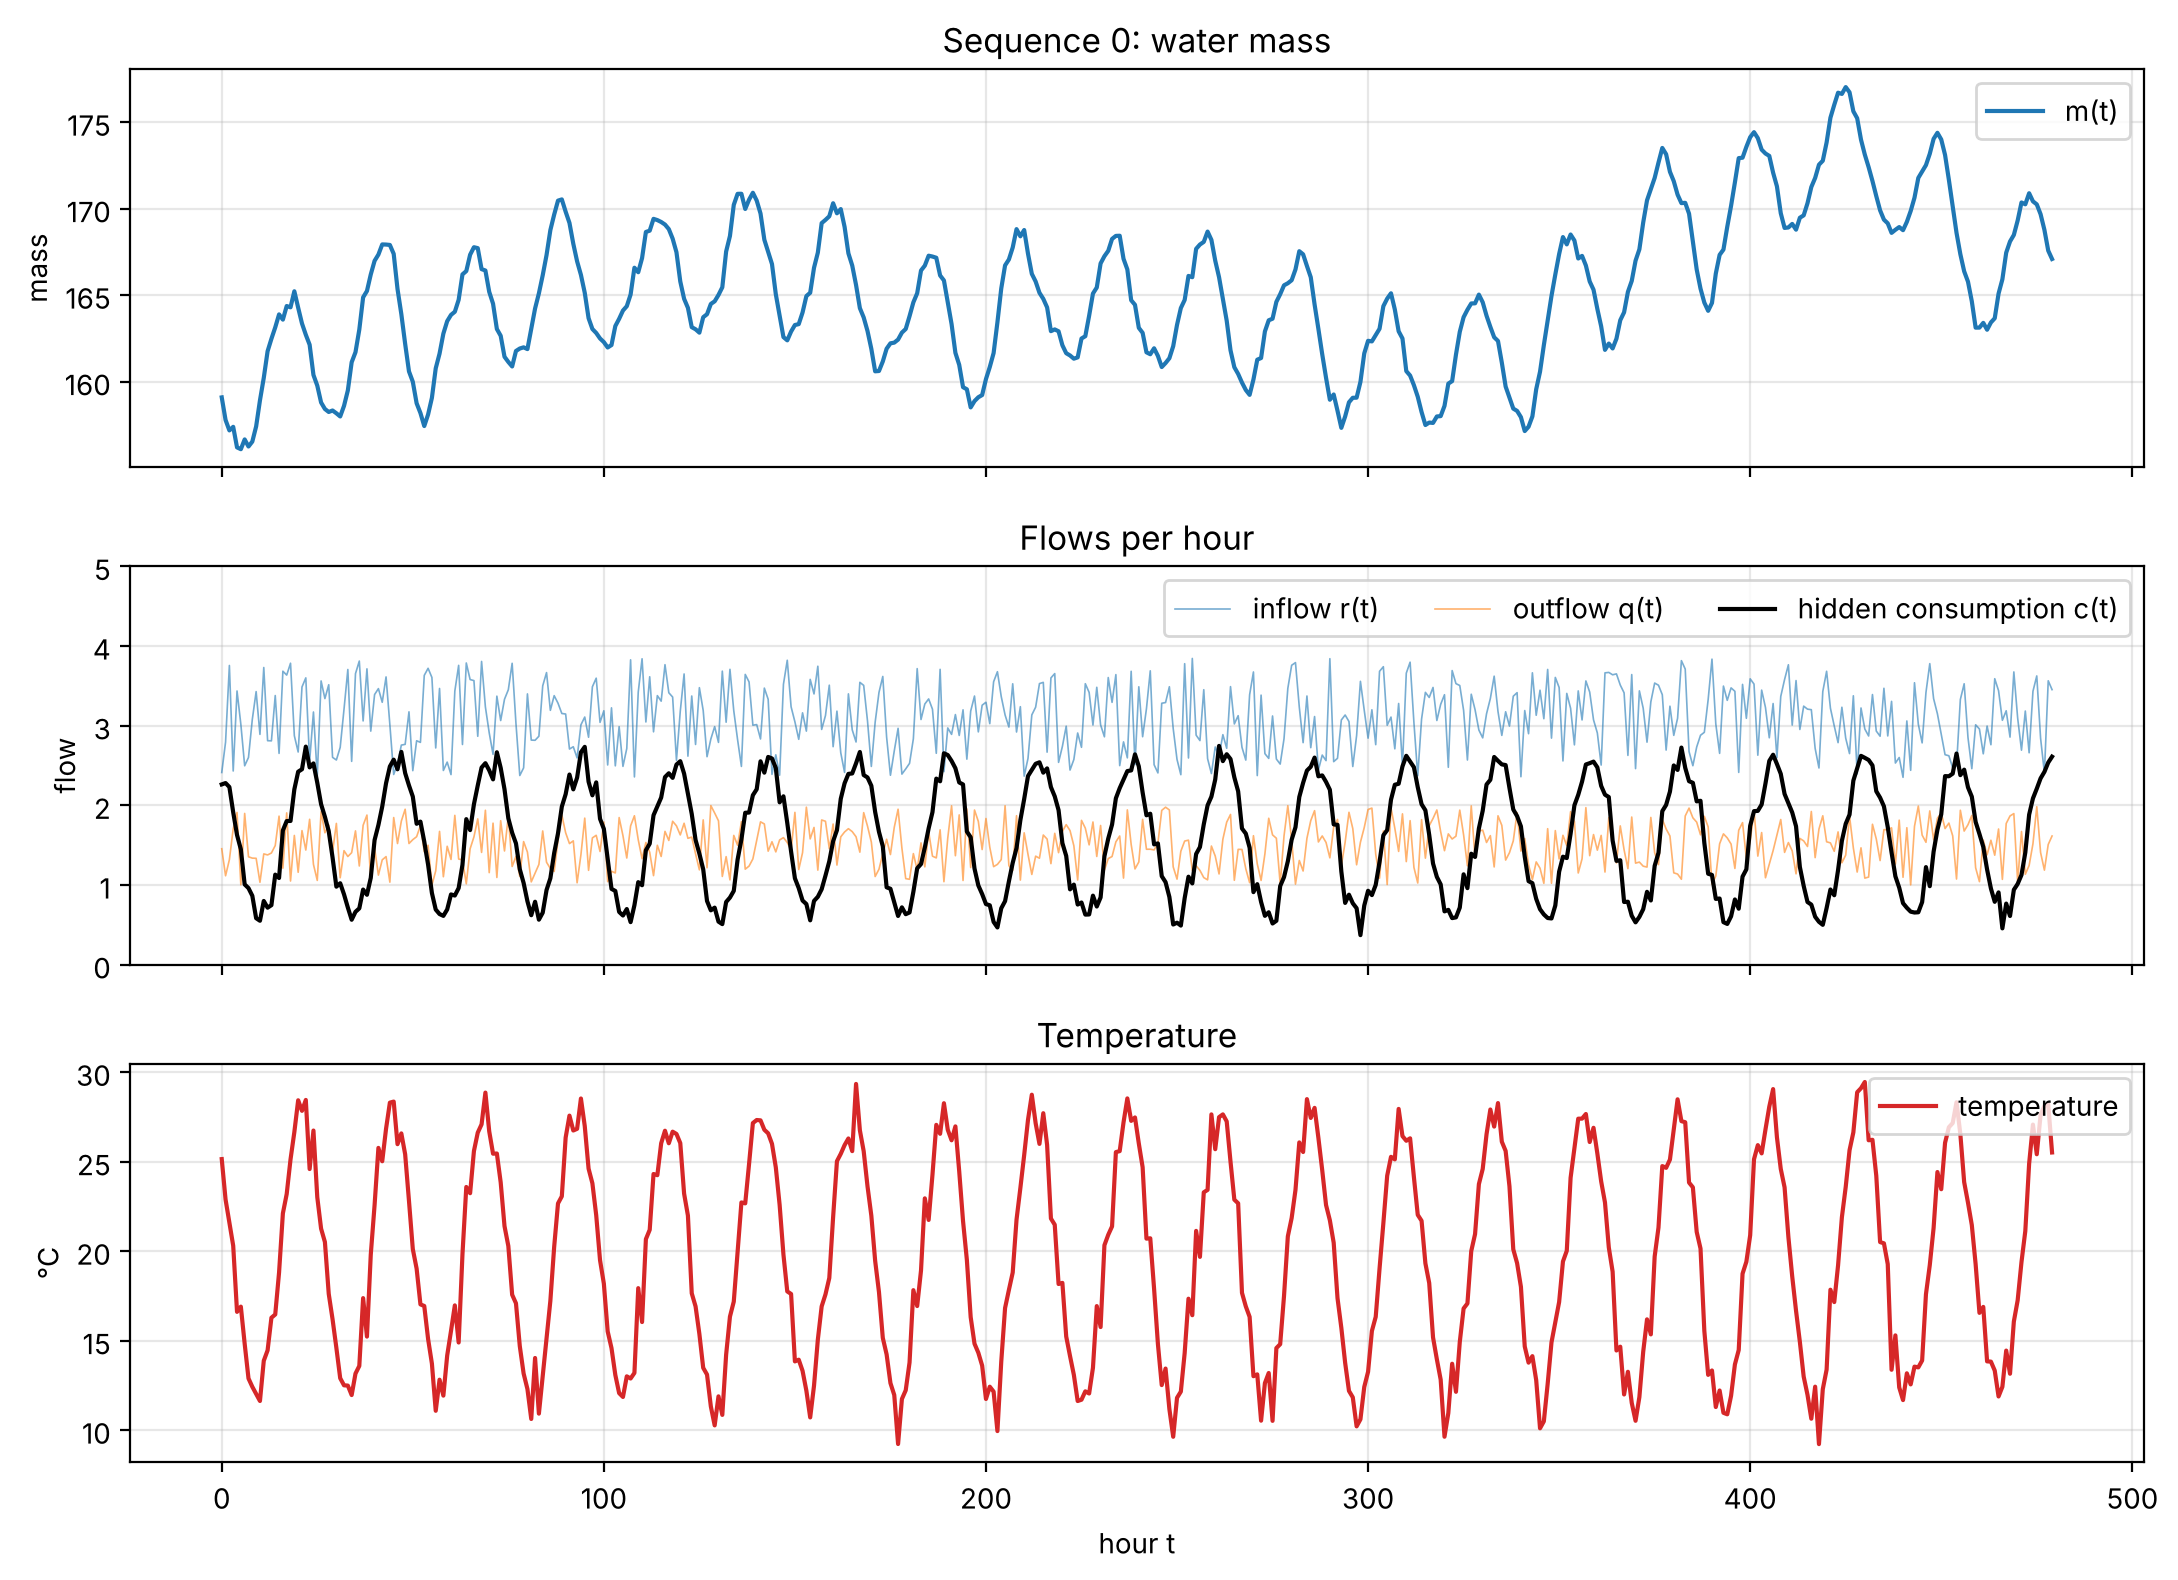

Sequence 0: m in [156.1, 177.0], c in [0.37, 2.75], temp in [9.2, 29.5]
All data:   m in [80.3, 250.3], c in [0.15, 3.01], temp in [6.0, 33.2]


In [6]:
seq = 0
hours = np.arange(CONFIG["T"])
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].plot(hours, np.asarray(X[seq, :, 0]), color="tab:blue", label="m(t)")
axes[0].set_title(f"Sequence {seq}: water mass")
axes[0].set_ylabel("mass")

axes[1].plot(hours, np.asarray(X[seq, :, 1]), lw=0.6, alpha=0.6, label="inflow r(t)")
axes[1].plot(hours, np.asarray(X[seq, :, 2]), lw=0.6, alpha=0.6, label="outflow q(t)")
axes[1].plot(hours, np.asarray(C[seq]), lw=1.5, color="black", label="hidden consumption c(t)")
axes[1].set_title("Flows per hour")
axes[1].set_ylabel("flow")
axes[1].set_ylim(0, 5)                     # room for the legend above the curves

axes[2].plot(hours, np.asarray(X[seq, :, 3]), color="tab:red", label="temperature")
axes[2].set_title("Temperature")
axes[2].set_ylabel("°C")
axes[2].set_xlabel("hour t")

for ax in axes:
    ax.legend(loc="upper right", ncol=3)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Sequence {seq}: m in [{float(X[seq, :, 0].min()):.1f}, {float(X[seq, :, 0].max()):.1f}], "
      f"c in [{float(C[seq].min()):.2f}, {float(C[seq].max()):.2f}], "
      f"temp in [{float(X[seq, :, 3].min()):.1f}, {float(X[seq, :, 3].max()):.1f}]")
print(f"All data:   m in [{float(m.min()):.1f}, {float(m.max()):.1f}], "
      f"c in [{float(C.min()):.2f}, {float(C.max()):.2f}], temp in [{float(temp.min()):.1f}, {float(temp.max()):.1f}]")

assert len(axes) == 3, "three panels expected"
assert all(ax.get_title() and ax.get_ylabel() and ax.get_legend() for ax in axes), "every panel needs a title, a y label and a legend"

**Split and normalize.** Split train/test **by sequence**, not by timestep, so no timesteps from a test sequence leak into training through shared history. Normalize inputs (zero mean, unit variance) using statistics computed **only on the training split**. Keep the *unnormalized* `m(t)`, `r(t)`, `q(t)` around separately — you'll need the raw physical values later for the conservation-law reconstruction, which must not be done in normalized units.

### 4.3 Split, normalization and the shifted test set

`make_dataset` regenerates the data from a key and packs everything a run needs into one dictionary (a "bundle"):

- **Split by sequence:** sequences 0–299 are training (or only the first `n_train` of them), 300–349 validation, 350–449 test. Whole sequences go to one split, so no test step shares its history with a training step. The validation set is used for model selection; the test set is only measured.
- **Statistics from the training split only:** `x_mean`, `x_std` (one per feature) and `y_mean`, `y_std` (scalars) are computed on the training sequences actually used, in float64 for accuracy. They normalize the network inputs of all three splits (`Xn_*`).
- **Raw values kept:** `X_*` stay unnormalized, because the mass balance needs the physical `m, r, q`.
- `stats_from` copies the statistics of another bundle. The cold-spell bundle `DATA_SHIFT` (temperature 15 °C lower) uses it: a model trained on `DATA` must see shifted inputs through the *same* normalization it was trained with. Only its test split is used.

In [7]:
def make_dataset(key, n_train=300, unmetered_inflow=0.0, temp_shift=0.0, stats_from=None, tag="main"):
    """Generate the data and return a bundle: splits, statistics, normalized inputs.

    Inputs: key (PRNGKey); n_train (int <= 300, first n_train of sequences 0-299);
    unmetered_inflow, temp_shift (floats, passed to generate_data); stats_from (bundle or None:
    copy its statistics instead of computing them); tag (str naming the bundle).
    Output: dict with X_tr/X_va/X_te (n, T, 6) raw, Y_* and C_* (n, T), x_mean/x_std (6,),
    y_mean/y_std (floats), Xn_* (n, T, 6) normalized, and tag.
    """
    assert 0 < n_train <= CONFIG["n_train"], "n_train must be between 1 and 300"
    X, Y, C = generate_data(key, CONFIG["n_seq"], CONFIG["T"], unmetered_inflow, temp_shift)
    i_va = CONFIG["n_train"]                      # first validation sequence (300)
    i_te = CONFIG["n_train"] + CONFIG["n_val"]    # first test sequence (350)
    data = {
        "tag": tag,
        "X_tr": X[:n_train], "Y_tr": Y[:n_train], "C_tr": C[:n_train],
        "X_va": X[i_va:i_te], "Y_va": Y[i_va:i_te], "C_va": C[i_va:i_te],
        "X_te": X[i_te:], "Y_te": Y[i_te:], "C_te": C[i_te:],
    }
    if stats_from is None:
        X_tr64 = np.asarray(data["X_tr"], dtype=np.float64)
        Y_tr64 = np.asarray(data["Y_tr"], dtype=np.float64)
        data["x_mean"] = jnp.asarray(X_tr64.mean(axis=(0, 1)), dtype=jnp.float32)   # per feature
        data["x_std"] = jnp.asarray(X_tr64.std(axis=(0, 1)), dtype=jnp.float32)
        data["y_mean"] = float(Y_tr64.mean())
        data["y_std"] = float(Y_tr64.std())
    else:
        for k in ("x_mean", "x_std", "y_mean", "y_std"):
            data[k] = stats_from[k]
    for s in ("tr", "va", "te"):
        data[f"Xn_{s}"] = (data[f"X_{s}"] - data["x_mean"]) / data["x_std"]
    return data


DATA = make_dataset(data_key)
DATA_SHIFT = make_dataset(data_key, temp_shift=CONFIG["temp_shift"], stats_from=DATA, tag="shift")

for s in ("tr", "va", "te"):
    print(f"{s}: X {DATA['X_' + s].shape}, Y {DATA['Y_' + s].shape}, C {DATA['C_' + s].shape}")
print("x_mean:", np.round(np.asarray(DATA["x_mean"]), 3))
print("x_std :", np.round(np.asarray(DATA["x_std"]), 3))
print(f"y_mean = {DATA['y_mean']:.3f}, y_std = {DATA['y_std']:.3f}")

Xn_tr64 = np.asarray(DATA["Xn_tr"], dtype=np.float64)
norm_mean, norm_std = Xn_tr64.mean(axis=(0, 1)), Xn_tr64.std(axis=(0, 1))
print("normalized training mean:", np.round(norm_mean, 5), " std:", np.round(norm_std, 5))
full_mean = np.asarray(X, dtype=np.float64).mean(axis=(0, 1))            # statistics of all 450 sequences
print("x_mean from the full data (must differ):", np.round(full_mean, 3))

train_idx, val_idx, test_idx = set(range(0, 300)), set(range(300, 350)), set(range(350, 450))
DATA_25 = make_dataset(data_key, n_train=25, tag="n25")
temp_change = np.asarray(DATA_SHIFT["X_te"][..., 3] - DATA["X_te"][..., 3])
share_c0_shift = float(jnp.mean(DATA_SHIFT["C_te"] == 0))
print(f"DATA_SHIFT: test temperature change in [{temp_change.min():.4f}, {temp_change.max():.4f}]; "
      f"share of test steps with c = 0: {share_c0_shift:.1%} (main data: {float(jnp.mean(DATA['C_te'] == 0)):.1%})")

assert DATA["X_tr"].shape == (300, 480, 6) and DATA["X_va"].shape == (50, 480, 6) and DATA["X_te"].shape == (100, 480, 6), "wrong split shapes"
assert not (train_idx & val_idx) and not (train_idx & test_idx) and not (val_idx & test_idx), "index ranges overlap"
assert np.all(np.abs(norm_mean) < 1e-3) and np.all(np.abs(norm_std - 1) < 1e-3), "training inputs are not normalized"
assert not np.allclose(full_mean, np.asarray(DATA["x_mean"])), "statistics look like full-data statistics"
assert DATA_25["X_tr"].shape[0] == 25, "the n_train=25 bundle must have 25 training sequences"
assert bool(jnp.array_equal(DATA_25["X_va"], DATA["X_va"])) and bool(jnp.array_equal(DATA_25["X_te"], DATA["X_te"])), \
    "validation and test sets must not depend on n_train"
assert bool(jnp.array_equal(DATA_SHIFT["x_mean"], DATA["x_mean"])), "DATA_SHIFT must reuse DATA's statistics"
assert np.all(np.abs(temp_change + 15.0) < 1e-3), "the shifted test temperature must be 15 degrees lower"
del DATA_25   # only needed for the check

tr: X (300, 480, 6), Y (300, 480), C (300, 480)
va: X (50, 480, 6), Y (50, 480), C (50, 480)
te: X (100, 480, 6), Y (100, 480), C (100, 480)
x_mean: [156.477   3.098   1.499  19.886   0.479   0.495]
x_std : [16.676  0.433  0.288  5.824  0.288  0.284]
y_mean = 156.482, y_std = 16.721
normalized training mean: [-0.  0. -0. -0. -0.  0.]  std: [1. 1. 1. 1. 1. 1.]
x_mean from the full data (must differ): [156.079   3.099   1.499  19.91    0.479   0.497]


DATA_SHIFT: test temperature change in [-15.0000, -15.0000]; share of test steps with c = 0: 14.4% (main data: 0.0%)


<a id='5'></a>
## 5. Task 5.2 — Conventional LSTM (the baseline, Option 1)

A standard LSTM that receives the observable variables and **predicts the mass directly**:

$$ \hat{m}(t+1) = \text{LSTM}_\theta\big(x(t)\big) $$

It has no knowledge of the conservation law — it has to learn everything from data. This is your baseline.

**Implementation.** `LSTMBackbone` wraps one `nn.LSTMCell` in `nn.RNN`, which runs the cell over the time axis and returns the hidden state at every step, `(batch, T, hidden)`. The model is many-to-many: at step `t` the state has seen `x(0) … x(t)`, and the output at `t` is the prediction of `m(t+1)`. Flax initializes the recurrent weights orthogonally by default, which keeps the state's norm stable at the start of training.

`ConventionalLSTM` adds one `Dense(1)` head. Its raw output is a small number of order 1, while the target is around 155. The mapping to physical units, `m̂ = y_mean + y_std · output` with the fixed training statistics, is applied outside the module, in `build_model` (section 6).

**Parameters:** the LSTM cell has 4 input kernels (6 × 32, no bias) and 4 recurrent kernels (32 × 32 + 32 bias) = 4,992; the head adds 33. Total 5,025.

In [8]:
class LSTMBackbone(nn.Module):
    """Recurrent LSTM layer returning the hidden state at every step.

    Input xs: (batch, T, features). Output: (batch, T, hidden_size).
    """
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs):                     # xs: (batch, T, features)
        return nn.RNN(nn.LSTMCell(self.hidden_size))(xs)


class ConventionalLSTM(nn.Module):
    """Predicts m(t+1) directly. Input xs (normalized): (batch, T, 6). Output: (batch, T), unscaled."""
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs):                     # xs (normalized): (batch, T, 6)
        h = LSTMBackbone(self.hidden_size)(xs)
        return nn.Dense(1)(h).squeeze(-1)


def n_parameters(params):
    """Total number of scalar parameters in a parameter pytree."""
    return int(sum(p.size for p in jax.tree_util.tree_leaves(params)))


k_backbone, k_conv = jax.random.split(run_key("check21_s112358"))
xs_check = DATA["Xn_tr"][:2]
backbone = LSTMBackbone(CONFIG["hidden_size"])
h_check = backbone.apply(backbone.init(k_backbone, xs_check), xs_check)
conv_check = ConventionalLSTM(CONFIG["hidden_size"])
conv_check_params = conv_check.init(k_conv, xs_check)
out_check = conv_check.apply(conv_check_params, xs_check)
print("hidden states:", h_check.shape, " output:", out_check.shape, " parameters:", n_parameters(conv_check_params))

assert h_check.shape == (2, 480, 32), "hidden states must be (batch, T, hidden)"
assert out_check.shape == (2, 480), "output must be (batch, T)"
assert n_parameters(conv_check_params) == 5025, "the baseline must have 5,025 parameters"

hidden states: (2, 480, 32)  output: (2, 480)  parameters: 5025


<a id='6'></a>
## 6. Task 5.3 — Your model (the option your group chose in Phase A)

Implement **one** of the three non-baseline options from Phase A §2 — whichever your group chose and justified in Discussion 3. You only need the one matching your choice; the other two stubs below are there for reference (or if you want to compare more than one — optional, not required).

**Important, for all three options:** the model should receive `xs` **normalized** for the neural-network part, but must use the **original physical values** of `m`, `r`, `q` wherever the mass balance is used (reconstruction, or the physics loss term) — doing that arithmetic in normalized units would be physically meaningless.

### Option 2 — Soft constraint

Two outputs, `(m̂(t+1), ĉ(t))`, both learned — nothing in the architecture enforces the conservation law. Instead, an extra loss term penalizes violations:

$$ L = L_{\text{pred}} + \lambda\, L_{\text{physics}}, \qquad
L_{\text{pred}} = \big(\hat m(t{+}1)-m(t{+}1)\big)^2, \qquad
L_{\text{physics}} = \big(\hat m(t{+}1)-m(t)-r(t)+q(t)+\hat c(t)\big)^2 $$

`λ` is a new hyperparameter you choose — see §7 for how it plugs into training.

In [9]:
class SoftConstraintLSTM(nn.Module):
    """Option 2: predicts (m_hat, c_hat); conservation is only encouraged via the loss (see Sec.7)."""
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs_norm):
        # xs_norm: normalized network input (batch, T, 6)
        # TODO:
        #   1. h = LSTMBackbone(...)(xs_norm)
        #   2. two separate Dense(1) heads on h -> m_hat, c_hat, each squeezed to (batch, T)
        #   3. return m_hat, c_hat
        raise NotImplementedError


### Option 3 — Hard constraint (conservative architecture)

The network predicts only the hidden consumption; the mass is reconstructed analytically, so conservation holds exactly by construction:

$$ \hat{c}(t) = \text{softplus}\big(\text{LSTM}_\theta(x(t))\big) \ge 0
\qquad\Longrightarrow\qquad
\hat{m}(t+1) = m(t) + r(t) - q(t) - \hat{c}(t) $$

`softplus` is preferred over `relu` here: it's smooth and differentiable everywhere, so it won't stall learning at `ĉ=0`.

**Implementation (used in the ablation of section 8E.2).** The order of operations is fixed: `((m + r) − q) − ĉ`. `compute_metrics` (section 8) uses the same order to compute the implied consumption, so it gets back exactly `ĉ`'s sign. Because `ĉ > 0`, `fl(b − ĉ) ≤ b` for the float32 value `b = (m + r) − q`, so the implied consumption `b − m̂` is never negative and the physical error is exactly 0, even for untrained parameters.

In [10]:
class ConservativeLSTM(nn.Module):
    """Option 3: predicts hidden consumption c_hat(t) >= 0 and closes the mass balance exactly.

    Inputs: xs_norm (batch, T, 6) normalized; m_phys, r_phys, q_phys (batch, T) raw.
    Output: (m_pred, c_hat), each (batch, T), in physical units.
    """
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs_norm, m_phys, r_phys, q_phys):
        h = LSTMBackbone(self.hidden_size)(xs_norm)
        c_hat = nn.softplus(nn.Dense(1)(h).squeeze(-1))         # hard positivity constraint
        m_pred = ((m_phys + r_phys) - q_phys) - c_hat           # balance in RAW units, fixed order
        return m_pred, c_hat


xn_c, x_c = DATA["Xn_tr"][:2], DATA["X_tr"][:2]
opt3_check = ConservativeLSTM(CONFIG["hidden_size"])
opt3_check_params = opt3_check.init(run_key("check23_s112358"), xn_c, x_c[..., 0], x_c[..., 1], x_c[..., 2])
m3, c3 = opt3_check.apply(opt3_check_params, xn_c, x_c[..., 0], x_c[..., 1], x_c[..., 2])
m_c, r_c, q_c = np.asarray(x_c[..., 0]), np.asarray(x_c[..., 1]), np.asarray(x_c[..., 2])
implied_c3 = ((m_c + r_c) - q_c) - np.asarray(m3)                # float32, same order as the model
physical_error_3 = float(np.mean(np.maximum(0.0, -implied_c3)))
print("outputs:", m3.shape, c3.shape, " parameters:", n_parameters(opt3_check_params),
      f" physical error (untrained): {physical_error_3}")

assert m3.shape == (2, 480) and c3.shape == (2, 480), "outputs must be (batch, T)"
assert n_parameters(opt3_check_params) == 5025, "Option 3 must have 5,025 parameters"
assert physical_error_3 == 0.0, "Option 3's physical error must be exactly 0"

outputs: (2, 480) (2, 480)  parameters: 5025  physical error (untrained): 0.0


### Option 4 — Residual correction

Like Option 3, but the network also predicts a small correction `δ(t)` to absorb unmodelled effects:

$$ \hat{m}(t+1) = m(t) + r(t) - q(t) - \hat{c}(t) + \delta(t) $$

Useful if you think the conservation law alone doesn't fully capture the true dynamics — but conservation is no longer exact, so watch how large `δ(t)` grows in §8's physical-error metric.

**Implementation (our model).** Two heads on the same hidden state: `ĉ = softplus(head_c)` is the modelled consumption (never negative) and `δ = head_δ` is an unconstrained correction. The next mass is computed from the balance in raw physical units, `m̂ = ((m + r) − q) − ĉ + δ`. Only the network input is normalized.

What the network learns is therefore the small hidden term (order 1), not the whole mass (order 150). The gradient of the loss flows from `m̂` back through this fixed, parameter-free arithmetic into both heads. Note that only `ĉ − δ` enters `m̂`, so the loss cannot tell the two terms apart (the identifiability issue noted in Phase A).

Parameters: 4,992 (LSTM) + 33 + 33 (two heads) = 5,058.

In [11]:
class ResidualCorrectionLSTM(nn.Module):
    """Option 4: hard constraint plus a small learned correction delta(t).

    Inputs: xs_norm (batch, T, 6) normalized; m_phys, r_phys, q_phys (batch, T) raw.
    Output: (m_pred, c_hat, delta), each (batch, T), in physical units.
    """
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs_norm, m_phys, r_phys, q_phys):
        h = LSTMBackbone(self.hidden_size)(xs_norm)
        c_hat = nn.softplus(nn.Dense(1, name="head_c")(h).squeeze(-1))   # >= 0
        delta = nn.Dense(1, name="head_delta")(h).squeeze(-1)            # no constraint
        m_pred = ((m_phys + r_phys) - q_phys) - c_hat + delta            # RAW units, fixed order
        return m_pred, c_hat, delta


opt4_check = ResidualCorrectionLSTM(CONFIG["hidden_size"])
opt4_check_params = opt4_check.init(run_key("check22_s112358"), xn_c, x_c[..., 0], x_c[..., 1], x_c[..., 2])
m4, c4, d4 = opt4_check.apply(opt4_check_params, xn_c, x_c[..., 0], x_c[..., 1], x_c[..., 2])
balance_gap_4 = float(np.max(np.abs(np.asarray(m4) - (((m_c + r_c) - q_c) - np.asarray(c4) + np.asarray(d4)))))
print("outputs:", m4.shape, c4.shape, d4.shape, " parameters:", n_parameters(opt4_check_params))
print(f"min c_hat = {float(c4.min()):.4f}; max |m_pred - balance| = {balance_gap_4:.2e}")

assert m4.shape == c4.shape == d4.shape == (2, 480), "three outputs of shape (batch, T)"
assert n_parameters(opt4_check_params) == 5058, "Option 4 must have 5,058 parameters"
assert bool(jnp.all(c4 > 0)), "c_hat must be positive"
assert balance_gap_4 < 1e-3, "m_pred must equal ((m + r) - q) - c_hat + delta in raw units"

outputs: (2, 480) (2, 480) (2, 480)  parameters: 5058
min c_hat = 0.4052; max |m_pred - balance| = 0.00e+00


### A uniform interface for the three models

The three models take different arguments and return different outputs. `build_model` hides that, so the training and evaluation code is the same for all of them:

- `init_fn(key)` creates the parameters, using one training sequence as the dummy input.
- `predict_fn(params, xn, x_raw)` returns `(m_pred, c_hat, delta)` in physical units. `xn` is the normalized input of the network; the raw `m, r, q` are read from `x_raw`. The baseline returns `c_hat = delta = None`; Option 3 returns `delta = 0`.
- For the baseline, `m_pred = y_mean + y_std · output` with the fixed training statistics of the bundle (`output_scaling=True`), or the raw output itself for the ablation of section 8E.2.

In [12]:
def build_model(kind, data, output_scaling=True):
    """Return (model, init_fn, predict_fn) for kind in {"baseline", "option4", "option3"}.

    data: the bundle whose training statistics scale the baseline's output.
    init_fn(key) -> params. predict_fn(params, xn (B, T, 6), x_raw (B, T, 6)) -> (m_pred, c_hat, delta),
    each (B, T) or None, in physical units.
    """
    hidden = CONFIG["hidden_size"]
    xn0, x0 = data["Xn_tr"][:1], data["X_tr"][:1]          # dummy input: one training sequence

    if kind == "baseline":
        model = ConventionalLSTM(hidden)
        y_mean, y_std = data["y_mean"], data["y_std"]

        def init_fn(key):
            return model.init(key, xn0)

        def predict_fn(params, xn, x_raw):
            out = model.apply(params, xn)
            m_pred = y_mean + y_std * out if output_scaling else out
            return m_pred, None, None

    elif kind in ("option4", "option3"):
        model = ResidualCorrectionLSTM(hidden) if kind == "option4" else ConservativeLSTM(hidden)

        def init_fn(key):
            return model.init(key, xn0, x0[..., 0], x0[..., 1], x0[..., 2])

        def predict_fn(params, xn, x_raw):
            outputs = model.apply(params, xn, x_raw[..., 0], x_raw[..., 1], x_raw[..., 2])
            if kind == "option4":
                return outputs
            m_pred, c_hat = outputs
            return m_pred, c_hat, jnp.zeros_like(c_hat)
    else:
        raise ValueError(f"unknown model kind: {kind}")
    return model, init_fn, predict_fn


xn2, x2 = DATA["Xn_tr"][:2], DATA["X_tr"][:2]
build_keys = dict(zip(["baseline", "option4", "option3"], jax.random.split(run_key("check24_s112358"), 3)))
for kind, k in build_keys.items():
    _, init_check, predict_check = build_model(kind, DATA)
    p_check = init_check(k)
    m_pred_check, c_hat_check, delta_check = predict_check(p_check, xn2, x2)
    print(f"{kind:9s}: m_pred {m_pred_check.shape}, mean {float(m_pred_check.mean()):.2f} "
          f"(y_mean {DATA['y_mean']:.2f}, y_std {DATA['y_std']:.2f}); c_hat is None: {c_hat_check is None}")
    assert m_pred_check.shape == (2, 480), "m_pred must be (batch, T)"
    assert abs(float(m_pred_check.mean()) - DATA["y_mean"]) < 2 * DATA["y_std"], "predictions must be in physical units"

raw_model, _, predict_raw = build_model("baseline", DATA, output_scaling=False)
_, init_scaled, _ = build_model("baseline", DATA)
p_raw = init_scaled(build_keys["baseline"])
raw_out = predict_raw(p_raw, xn2, x2)[0]
print(f"output_scaling=False: mean output {float(raw_out.mean()):.3f}")
assert bool(jnp.array_equal(raw_out, raw_model.apply(p_raw, xn2))), "output_scaling=False must return the raw output"

baseline : m_pred (2, 480), mean 154.28 (y_mean 156.48, y_std 16.72); c_hat is None: True


option4  : m_pred (2, 480), mean 176.94 (y_mean 156.48, y_std 16.72); c_hat is None: False


option3  : m_pred (2, 480), mean 176.81 (y_mean 156.48, y_std 16.72); c_hat is None: False


output_scaling=False: mean output -0.132


<a id='7'></a>
## 7. Task 5.4 — Train the baseline model and your model under identical conditions

- **Baseline (§5, Option 1):** MSE on `m(t+1)` directly.
- **Your model (§6):** the loss depends on which option you implemented —
  - **Option 2 (soft constraint):** `L = L_pred + λ·L_physics` (§6). `λ` is an extra hyperparameter — try a few values (e.g. `0.1, 1.0, 10.0`) and see how it trades off prediction accuracy against conservation.
  - **Option 3 (hard constraint) / Option 4 (residual correction):** MSE on the *reconstructed* `m̂(t+1)`, not on `ĉ(t)` directly — the true `c(t)` must not be used for supervision.
- Same optimizer, learning rate, hidden size, and number of epochs for both models — otherwise you're no longer measuring the effect of the architecture alone. Reasonable starting values: `hidden_size=32`, `Adam(learning_rate=1e-2)`, `~300` epochs, `batch_size=32` sequences.
- **Use mini-batch training**: at each step, sample (or shuffle-and-slice) a batch of `batch_size` sequences from the training set rather than using all sequences at once. Reshuffle sequence order at the start of every epoch, using `jax.random.permutation` (splitting your key each time) so the shuffling stays reproducible.
- Wrap the training step in `jax.jit` and record training time for both models.
- Plot training loss curves for both on the same axes (log scale is usually clearer).

In [13]:
def make_train_step(loss_fn, optimizer):
    @jax.jit
    def step(params, opt_state, batch):
        loss, grads = jax.value_and_grad(loss_fn)(params, batch)
        updates, opt_state = optimizer.update(grads, opt_state, params)
        params = optax.apply_updates(params, updates)
        return params, opt_state, loss
    return step

HIDDEN_SIZE = CONFIG["hidden_size"]
EPOCHS = CONFIG["epochs"]
BATCH_SIZE = CONFIG["batch_size"]
# Clip the global gradient norm, then Adam. The same optimizer for every run.
optimizer = optax.chain(optax.clip_by_global_norm(CONFIG["clip_norm"]),
                        optax.adam(CONFIG["learning_rate"]))


def make_loss_fn(predict_fn, mu=0.0):
    """Loss of one batch: MSE on m(t+1) in physical units, plus mu * mean(delta^2) when mu > 0.

    predict_fn: from build_model. batch: dict with xn, x (B, T, 6) and y (B, T). Output: scalar.
    """
    def loss_fn(params, batch):
        m_pred, c_hat, delta = predict_fn(params, batch["xn"], batch["x"])
        loss = jnp.mean((m_pred - batch["y"]) ** 2)
        if mu > 0 and delta is not None:      # Python-level condition, fixed when the function is built
            loss = loss + mu * jnp.mean(delta ** 2)
        return loss
    return loss_fn


def make_val_fn(predict_fn, data):
    """Jitted validation MSE (no penalty term) on the bundle's validation split. Output: scalar."""
    @jax.jit
    def val_fn(params):
        m_pred = predict_fn(params, data["Xn_va"], data["X_va"])[0]
        return jnp.mean((m_pred - data["Y_va"]) ** 2)
    return val_fn


def train_model(model, params, loss_fn, key, X_xs, extra_arrays, y, epochs=EPOCHS, batch_size=BATCH_SIZE,
                val_fn=None, run_name=""):
    """Mini-batch training with per-epoch validation and best-epoch selection.

    model: unused here (kept for the template's signature); the optimizer is the global `optimizer`.
    params: initial parameters. loss_fn(params, batch) -> scalar. key: PRNGKey for the shuffling.
    X_xs: normalized inputs (N, T, 6). extra_arrays: dict of other per-sequence arrays put in every
    batch (here {"x": raw inputs (N, T, 6)}). y: targets (N, T). val_fn(params) -> validation MSE, or None.
    Returns (best_params, history) with history = {"train": [...], "val": [...], "best_epoch": int
    (1-based), "batch_sizes": sizes of the batches of one epoch, "batch_keys": keys of a batch}.
    With val_fn=None the parameters of the last epoch are returned.
    """
    step = make_train_step(loss_fn, optimizer)       # jitted once per run
    opt_state = optimizer.init(params)
    n = X_xs.shape[0]
    history = {"train": [], "val": [], "best_epoch": epochs, "batch_sizes": [], "batch_keys": []}
    best_params, best_val = params, np.inf

    for epoch in range(1, epochs + 1):
        key, k_perm = jax.random.split(key)           # a fresh key for every epoch
        perm = jax.random.permutation(k_perm, n)
        losses, sizes = [], []
        for b, start in enumerate(range(0, n, batch_size)):   # the last batch may be smaller
            idx = perm[start:start + batch_size]
            batch = {"xn": X_xs[idx], "y": y[idx], **{k: v[idx] for k, v in extra_arrays.items()}}
            params, opt_state, loss = step(params, opt_state, batch)
            loss = float(loss)
            if not np.isfinite(loss):
                raise ValueError(f"Run {run_name}: loss is NaN at epoch {epoch}, batch {b}.")
            losses.append(loss)
            sizes.append(len(idx))
        # Epoch loss = mean over all training sequences (batches weighted by their size).
        history["train"].append(float(np.average(losses, weights=sizes)))
        history["batch_sizes"], history["batch_keys"] = sizes, sorted(batch)
        if val_fn is not None:
            val = float(val_fn(params))
            history["val"].append(val)
            if val < best_val:
                best_val, best_params, history["best_epoch"] = val, params, epoch
    if val_fn is None:
        best_params = params
    return best_params, history

**Training loop.** One function trains every model:

- At the start of every epoch the key is split and `jax.random.permutation` reshuffles the training sequences; they are then sliced into batches of 32 (300 sequences → 10 batches, the last of 12).
- The update step is jitted once per run. JAX compiles it once per batch shape, so twice (32 and 12 sequences).
- **Gradient clipping** (global norm 1.0, before Adam) protects the LSTM against occasional exploding gradients through 480 steps. Every model uses it.
- **Best epoch:** after every epoch the validation MSE is computed, and the parameters with the lowest value are kept. Training always runs all epochs, so the training times are comparable. This uses the validation set, never the test set.
- A `NaN` or infinite loss stops training with a message naming the run, the epoch and the batch.

The check below is a 3-epoch trial of the baseline, and a loss that returns `NaN` on purpose.

In [14]:
k_init_t, k_train_t = jax.random.split(run_key("trial31_s112358"))
_, init_t, predict_t = build_model("baseline", DATA)
params_t = init_t(k_init_t)
val_fn_t = make_val_fn(predict_t, DATA)
best_t, hist_t = train_model(None, params_t, make_loss_fn(predict_t), k_train_t, DATA["Xn_tr"],
                             {"x": DATA["X_tr"]}, DATA["Y_tr"], epochs=3, val_fn=val_fn_t, run_name="trial31_s112358")
val_of_best = float(val_fn_t(best_t))
print("train:", np.round(hist_t["train"], 3), " val:", np.round(hist_t["val"], 4), " best epoch:", hist_t["best_epoch"])
print("batch sizes:", hist_t["batch_sizes"], " batch keys:", hist_t["batch_keys"])
print(f"validation MSE of the returned parameters: {val_of_best:.6f}")

def nan_loss(params, batch):
    """A loss that is always NaN, to test the divergence stop."""
    return make_loss_fn(predict_t)(params, batch) * jnp.nan

try:
    train_model(None, params_t, nan_loss, k_train_t, DATA["Xn_tr"], {"x": DATA["X_tr"]}, DATA["Y_tr"],
                epochs=1, run_name="nan_test")
    nan_message = None
except ValueError as err:
    nan_message = str(err)
print("NaN test:", nan_message)

assert len(hist_t["train"]) == 3 and len(hist_t["val"]) == 3, "3 training and 3 validation values expected"
assert np.all(np.isfinite(hist_t["train"] + hist_t["val"])), "losses must be finite"
assert len(hist_t["batch_sizes"]) == 10 and hist_t["batch_sizes"][-1] == 12, "10 batches per epoch, the last of 12"
assert hist_t["batch_keys"] == ["x", "xn", "y"], "a batch must have exactly the keys xn, x, y (no C)"
assert abs(val_of_best - min(hist_t["val"])) < 1e-6, "the returned parameters must be those of the best epoch"
assert nan_message == "Run nan_test: loss is NaN at epoch 1, batch 0.", "a NaN loss must raise the FR4.6 message"

train: [175.536  40.791  11.672]  val: [49.3517 12.6133  4.9454]  best epoch: 3
batch sizes: [32, 32, 32, 32, 32, 32, 32, 32, 32, 12]  batch keys: ['x', 'xn', 'y']
validation MSE of the returned parameters: 4.945366


NaN test: Run nan_test: loss is NaN at epoch 1, batch 0.


### Running and caching an experiment

`run_experiment` does one complete run: it derives the run's keys from the seed and the name, builds and initializes the model, trains it (timed, including the one-off compilation), and computes the predictions of the best parameters on the test split of `data` and of each bundle in `eval_sets`. Everything is returned as NumPy arrays and floats; the trained parameters are not kept.

`run_cached` wraps it. It records the run's arguments in `RUN_NAMES` (asking for a known name with different arguments raises an error, so two different runs can never share a key), and saves each result to `results/<name>.npz`. If the file exists, it is loaded instead of retraining, so re-running the notebook takes seconds. Delete `results/` (or set `CONFIG["use_cache"] = False`) after changing the code, because the files do not record which code produced them.

**Rule for `eval_sets`:** every run trained on the full `DATA` also predicts on the cold-spell test set, `eval_sets={"shift": DATA_SHIFT}`. Runs with other training statistics (low data, incomplete physics) do not.

In [15]:
def run_experiment(name, kind, data, seed=CONFIG["seed"], mu=0.0, output_scaling=True, eval_sets=None,
                   epochs=CONFIG["epochs"]):
    """Train one model and return its results as NumPy arrays and floats.

    Inputs: name (str ending in _s<seed>); kind ("baseline", "option4", "option3"); data (bundle);
    seed (int); mu (float, weight of mean(delta^2)); output_scaling (bool, baseline only);
    eval_sets (dict name -> bundle, test splits to predict on); epochs (int).
    Output: dict with train_loss (epochs,), val_loss (epochs,), best_epoch, time, n_params, batch_keys,
    and for each evaluated set s ("test", then the eval_sets names): s_m_pred (100, T) and,
    when the model has them, s_c_hat and s_delta (100, T).
    """
    assert name.endswith(f"_s{seed}"), f"run name {name} must end with _s{seed}"
    k_init, k_train = jax.random.split(run_key(name, seed))
    model, init_fn, predict_fn = build_model(kind, data, output_scaling)
    params = init_fn(k_init)

    t0 = time.time()
    best_params, history = train_model(model, params, make_loss_fn(predict_fn, mu), k_train, data["Xn_tr"],
                                       {"x": data["X_tr"]}, data["Y_tr"], epochs=epochs,
                                       val_fn=make_val_fn(predict_fn, data), run_name=name)
    train_time = time.time() - t0

    result = {"train_loss": np.array(history["train"]), "val_loss": np.array(history["val"]),
              "best_epoch": history["best_epoch"], "time": train_time, "n_params": n_parameters(params),
              "batch_keys": np.array(history["batch_keys"])}
    predict_jit = jax.jit(predict_fn)
    for set_name, bundle in [("test", data)] + list((eval_sets or {}).items()):
        m_pred, c_hat, delta = predict_jit(best_params, bundle["Xn_te"], bundle["X_te"])
        result[f"{set_name}_m_pred"] = np.asarray(m_pred)
        if c_hat is not None:
            result[f"{set_name}_c_hat"] = np.asarray(c_hat)
            result[f"{set_name}_delta"] = np.asarray(delta)
    return result


def run_cached(name, kind, data, seed=CONFIG["seed"], mu=0.0, output_scaling=True, eval_sets=None,
               epochs=CONFIG["epochs"]):
    """run_experiment with a cache in results/<name>.npz; same inputs and output.

    Records (kind, data tag, seed, mu, output_scaling, epochs) in RUN_NAMES and raises ValueError
    if the name was already used with different arguments.
    """
    args = (kind, data["tag"], seed, mu, output_scaling, epochs)
    if name in RUN_NAMES and RUN_NAMES[name] != args:
        raise ValueError(f"Run name {name} already used with {RUN_NAMES[name]}, now asked with {args}.")
    RUN_NAMES[name] = args

    path = os.path.join("results", f"{name}.npz")
    if CONFIG["use_cache"] and os.path.exists(path):
        with np.load(path) as f:
            # 0-d arrays (scalars) back to Python numbers.
            result = {k: (f[k].item() if f[k].ndim == 0 else f[k]) for k in f.files}
        status = "loaded from cache"
    else:
        result = run_experiment(name, kind, data, seed, mu, output_scaling, eval_sets, epochs)
        np.savez(path, **result)
        status = "computed"
    print(f"{name}: {status} (training time {result['time']:.1f} s)")
    return result

**Check of the cache** with a 2-epoch trial run. Its file and its `RUN_NAMES` entry are deleted at the end, so the trial leaves no trace in later cells.

In [16]:
trial_path = os.path.join("results", "trial_s112358.npz")
if os.path.exists(trial_path):          # left over from an interrupted run
    os.remove(trial_path)
trial = run_cached("trial_s112358", kind="baseline", data=DATA, epochs=2)
trial_again = run_cached("trial_s112358", kind="baseline", data=DATA, epochs=2)
print("keys:", sorted(trial))
print("test predictions:", trial["test_m_pred"].shape)
try:
    run_cached("trial_s112358", kind="baseline", data=DATA, epochs=3)
    clash_message = None
except ValueError as err:
    clash_message = str(err)
print("same name, different arguments:", clash_message)

expected_keys = {"train_loss", "val_loss", "best_epoch", "time", "n_params", "test_m_pred"}
assert expected_keys <= set(trial), "missing keys in the result"
assert trial["test_m_pred"].shape == (100, 480), "test predictions must be (100, 480)"
assert set(trial) == set(trial_again) and all(np.array_equal(trial[k], trial_again[k]) for k in trial), \
    "the cached result must be identical"
assert clash_message is not None, "a known name with different arguments must raise ValueError"

os.remove(trial_path)
del RUN_NAMES["trial_s112358"]

trial_s112358: computed (training time 2.0 s)
trial_s112358: loaded from cache (training time 2.0 s)
keys: ['batch_keys', 'best_epoch', 'n_params', 'test_m_pred', 'time', 'train_loss', 'val_loss']
test predictions: (100, 480)
same name, different arguments: Run name trial_s112358 already used with ('baseline', 'main', 112358, 0.0, True, 2), now asked with ('baseline', 'main', 112358, 0.0, True, 3).


**Main runs.** The baseline and Option 4 are trained for 300 epochs under identical settings. Each also predicts on the cold-spell test set, used in section 8E.5. `RESULTS` collects every run's results under a short label.

In [17]:
RESULTS = {}
RESULTS["baseline"] = run_cached("baseline_s112358", kind="baseline", data=DATA, eval_sets={"shift": DATA_SHIFT})

baseline_s112358: computed (training time 63.3 s)


Option 4, same settings, then the FR4 check for both runs: 300 values each, a training loss that went down, and the best epoch.

In [18]:
RESULTS["opt4"] = run_cached("opt4_s112358", kind="option4", data=DATA, eval_sets={"shift": DATA_SHIFT})

for label in ("baseline", "opt4"):
    res = RESULTS[label]
    print(f"{label:8s}: first train loss {res['train_loss'][0]:.3f}, last {res['train_loss'][-1]:.5f}, "
          f"best epoch {res['best_epoch']} (val MSE {res['val_loss'].min():.5f}), time {res['time']:.1f} s")
    assert len(res["train_loss"]) == 300 and len(res["val_loss"]) == 300, f"{label}: 300 epochs expected"
    assert res["train_loss"][-1] < res["train_loss"][0], f"{label}: the training loss must go down"

opt4_s112358: computed (training time 68.0 s)
baseline: first train loss 212.976, last 0.01987, best epoch 253 (val MSE 0.01254), time 63.3 s
opt4    : first train loss 0.510, last 0.01007, best epoch 271 (val MSE 0.00992), time 68.0 s


**Loss curves.** Training (solid) and validation (dashed) MSE per epoch, in physical units, on log-scale axes. The dot marks the epoch whose parameters are kept.

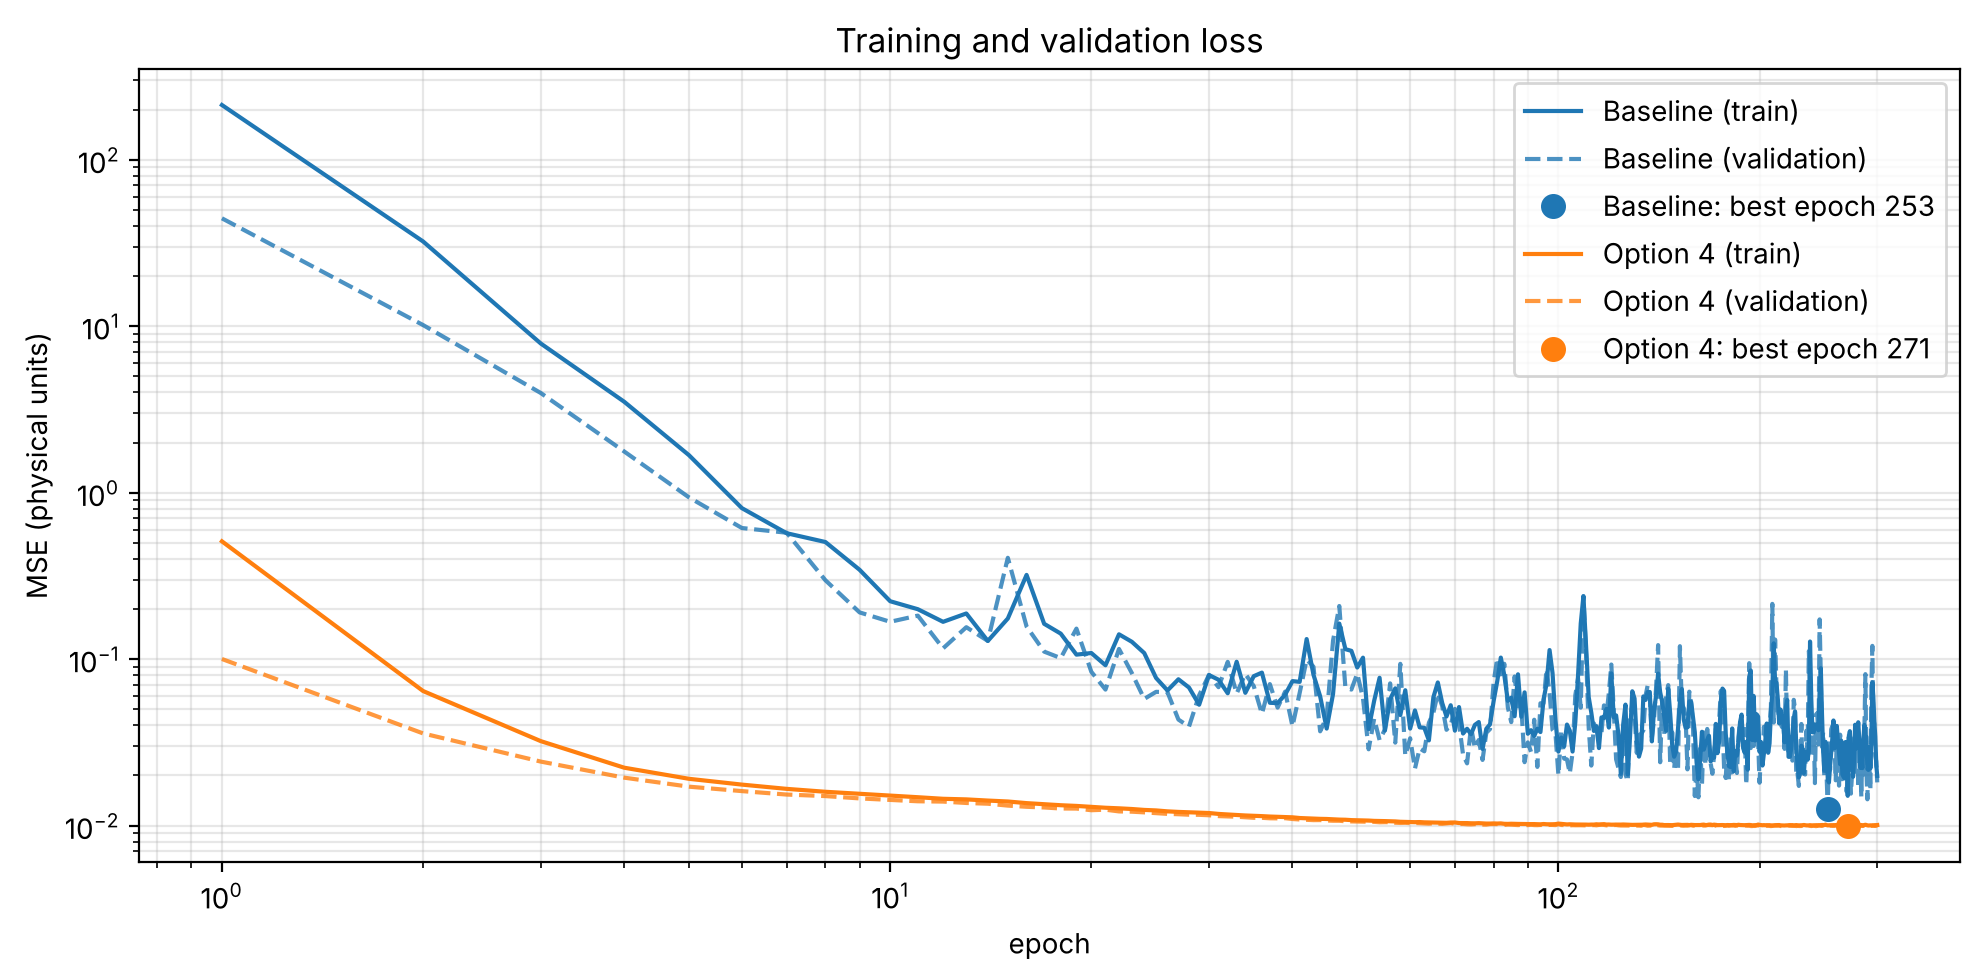

y scale: log | curves: 6


In [19]:
def plot_losses(runs):
    """Plot training (solid) and validation (dashed) curves of several runs, best epochs marked.

    runs: dict label -> result of run_cached. Returns the figure.
    """
    fig, ax = plt.subplots(figsize=(10, 5))
    for i, (label, res) in enumerate(runs.items()):
        color = f"C{i}"
        epochs = np.arange(1, len(res["train_loss"]) + 1)
        ax.plot(epochs, res["train_loss"], color=color, label=f"{label} (train)")
        ax.plot(epochs, res["val_loss"], color=color, ls="--", alpha=0.8, label=f"{label} (validation)")
        best = res["best_epoch"]
        ax.plot(best, res["val_loss"][best - 1], "o", color=color, ms=8,
                label=f"{label}: best epoch {best}")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_ylabel("MSE (physical units)")
    ax.set_title("Training and validation loss")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
    plt.tight_layout()
    plt.show()
    return fig


fig_losses = plot_losses({"Baseline": RESULTS["baseline"], "Option 4": RESULTS["opt4"]})
ax_l = fig_losses.axes[0]
print("y scale:", ax_l.get_yscale(), "| curves:", len(ax_l.get_lines()))
assert ax_l.get_yscale() == "log" and ax_l.get_legend() is not None, "log scale and legend expected"
assert len(ax_l.get_lines()) == 6, "two curves and one marker per model"

<a id='8'></a>
## 8. Metrics and comparison

Compute all four metrics on the **held-out test set** for both models:

| Metric | Formula |
|---|---|
| **MSE** | `mean((m̂(t+1) - m(t+1))^2)` |
| **MAE** | `mean(\|m̂(t+1) - m(t+1)\|)` |
| **Physical error** | `mean(max(0, -(m(t) + r(t) - q(t) - m̂(t+1))))` — magnitude of implied negative consumption |
| **Training time** | wall-clock time for the training loop |

**Expected pattern (depends on which option you implemented in §6):**
- The **baseline** (Option 1) should show a non-zero physical error — nothing stops it from implying negative consumption.
- **Option 2 (soft constraint):** physical error should be *reduced* relative to the baseline but generally still nonzero — how much depends on `λ`; larger `λ` should push it closer to zero, at some cost to MSE.
- **Option 3 (hard constraint):** physical error should be **exactly zero**, always — not just small. `softplus` guarantees `ĉ(t) ≥ 0`, so the implied consumption `m(t)+r(t)-q(t)-m̂(t+1) = ĉ(t)` can never be negative, regardless of training quality.
- **Option 4 (residual correction):** unlike Option 3, `δ(t)` has no positivity constraint, so physical error is generally nonzero — if `δ(t)` grows large, it can exceed Option 3's.

If your results don't roughly match the pattern for your chosen option, check: are both models trained under identical conditions? Does your model's mass computation (or physics loss term) use raw, unnormalized `m, r, q`? Is `c(t)` leaking into either model's inputs anywhere?

In [20]:
def compute_metrics(m_pred, m, r, q, y):
    """Return (mse, mae, physical_error). All inputs (N, T); m, r, q raw.

    The implied consumption ((m + r) - q) - m_pred is computed in float32 with the same order of
    operations as inside the models, so Option 3 gets back exactly the sign of c_hat.
    """
    m_pred, m, r, q = (np.asarray(a, dtype=np.float32) for a in (m_pred, m, r, q))
    err = m_pred.astype(np.float64) - np.asarray(y, dtype=np.float64)
    implied = ((m + r) - q) - m_pred
    physical_error = float(np.mean(np.maximum(0.0, -implied)))
    return float(np.mean(err ** 2)), float(np.mean(np.abs(err))), physical_error


def violation_rate(m_pred, m, r, q):
    """Share of time steps whose implied consumption ((m + r) - q) - m_pred is negative. Inputs (N, T)."""
    m_pred, m, r, q = (np.asarray(a, dtype=np.float32) for a in (m_pred, m, r, q))
    return float(np.mean((((m + r) - q) - m_pred) < 0))


def evaluate(result, data, prefix="test"):
    """Metrics of a run's stored predictions on the test split of `data`.

    result: dict from run_cached (or any dict with f"{prefix}_m_pred"). prefix: "test" or "shift".
    Output: dict with mse, mae, phys, viol, and, when the run has c_hat: mae_c (|c_hat - c|),
    mae_eff (|c_hat - delta - c|), mean_delta, mean_abs_delta, max_abs_delta. C is used only here.
    """
    x = np.asarray(data["X_te"])
    m, r, q = x[..., 0], x[..., 1], x[..., 2]
    m_pred = result[f"{prefix}_m_pred"]
    mse, mae, phys = compute_metrics(m_pred, m, r, q, data["Y_te"])
    out = {"mse": mse, "mae": mae, "phys": phys, "viol": violation_rate(m_pred, m, r, q)}
    if f"{prefix}_c_hat" in result:
        c_hat, delta = result[f"{prefix}_c_hat"], result[f"{prefix}_delta"]
        c_true = np.asarray(data["C_te"])
        out.update(mae_c=float(np.mean(np.abs(c_hat - c_true))),
                   mae_eff=float(np.mean(np.abs((c_hat - delta) - c_true))),
                   mean_delta=float(np.mean(delta)),
                   mean_abs_delta=float(np.mean(np.abs(delta))),
                   max_abs_delta=float(np.max(np.abs(delta))))
    return out


# Check on hand-made arrays (one sequence of 3 steps).
m_h = np.array([[100.0, 150.0, 200.0]], dtype=np.float32)
r_h = np.array([[3.0, 2.5, 3.5]], dtype=np.float32)
q_h = np.array([[1.0, 1.5, 2.0]], dtype=np.float32)
b_h = (m_h + r_h) - q_h                     # no consumption
y_h = b_h - 1.0
checks = {"equal to m + r - q": b_h, "0.5 above it": b_h + 0.5, "0.3 below it": b_h - 0.3}
for label, pred in checks.items():
    mse_h, mae_h, phys_h = compute_metrics(pred, m_h, r_h, q_h, y_h)
    print(f"prediction {label:18s}: MSE {mse_h:.3f}, MAE {mae_h:.3f}, physical error {phys_h:.3f}, "
          f"violation rate {violation_rate(pred, m_h, r_h, q_h):.2f}")
phys_values = [compute_metrics(p, m_h, r_h, q_h, y_h)[2] for p in checks.values()]
viol_values = [violation_rate(p, m_h, r_h, q_h) for p in checks.values()]

assert phys_values[0] == 0.0, "a prediction equal to m + r - q has physical error 0"
assert abs(phys_values[1] - 0.5) < 1e-6, "a prediction 0.5 above m + r - q has physical error 0.5"
assert phys_values[2] == 0.0, "a prediction below m + r - q has physical error 0"
assert viol_values == [0.0, 1.0, 0.0], "violation rates must be 0, 1 and 0"

prediction equal to m + r - q: MSE 1.000, MAE 1.000, physical error 0.000, violation rate 0.00
prediction 0.5 above it      : MSE 2.250, MAE 1.500, physical error 0.500, violation rate 1.00
prediction 0.3 below it      : MSE 0.490, MAE 0.700, physical error 0.000, violation rate 0.00


### Main comparison on the test set

Two **naive references** put the errors in context:

- **Persistence:** `m̂(t+1) = m(t)`, i.e. "nothing changes".
- **Constant consumption:** the balance with `c̄`, the mean implied consumption of the training split, `m̂ = m + r − q − c̄`. It uses the training targets, not `C`.

The table lists the test-set metrics of both references and both trained models. The second table holds Option 4's diagnostics of the hidden process (the only use of the true `C`).

In [21]:
def naive_references(data):
    """Metrics (as from evaluate) of persistence and of the constant-consumption balance on data's test split.

    Output: dict label -> metrics dict. c_bar is the mean of (m + r - q) - Y over the training split.
    """
    x_tr = np.asarray(data["X_tr"], dtype=np.float64)
    c_bar = float(np.mean(((x_tr[..., 0] + x_tr[..., 1]) - x_tr[..., 2]) - np.asarray(data["Y_tr"], np.float64)))
    x = np.asarray(data["X_te"])
    persistence = x[..., 0]
    constant = ((x[..., 0] + x[..., 1]) - x[..., 2]) - np.float32(c_bar)
    print(f"mean implied consumption of the training split: c_bar = {c_bar:.4f}")
    return {"Persistence": evaluate({"test_m_pred": persistence}, data),
            "Constant consumption": evaluate({"test_m_pred": constant}, data)}


def print_table(rows, columns):
    """Print a plain-text table.

    rows: list of (label, dict). columns: list of (key, header, format spec); a missing key prints blank.
    """
    widths = [max(len(h), 10) for _, h, _ in columns]
    label_width = max(len(label) for label, _ in rows) + 2
    print(" " * label_width + "  ".join(h.rjust(w) for (_, h, _), w in zip(columns, widths)))
    for label, values in rows:
        cells = [(format(values[k], f) if k in values and values[k] is not None else "").rjust(w)
                 for (k, _, f), w in zip(columns, widths)]
        print(label.ljust(label_width) + "  ".join(cells))


def metrics_of(label):
    """Test metrics of RESULTS[label], with its training time and best epoch."""
    res = RESULTS[label]
    return {**evaluate(res, DATA), "time": res["time"], "best_epoch": res["best_epoch"]}


MAIN_COLUMNS = [("mse", "MSE", ".5f"), ("mae", "MAE", ".4f"), ("phys", "phys. error", ".5f"),
                ("viol", "violations", ".3%"), ("time", "time (s)", ".1f")]
DIAG_COLUMNS = [("mae_c", "MAE c_hat", ".4f"), ("mae_eff", "MAE c-delta", ".4f"),
                ("mean_delta", "mean delta", ".4f"), ("mean_abs_delta", "mean |d|", ".4f"),
                ("max_abs_delta", "max |d|", ".4f")]

naive = naive_references(DATA)
main_rows = list(naive.items()) + [("Baseline (Option 1)", metrics_of("baseline")),
                                   ("Option 4", metrics_of("opt4"))]
print_table(main_rows, MAIN_COLUMNS)
print()
print_table([("Option 4", metrics_of("opt4"))], DIAG_COLUMNS)

all_values = [v for _, row in main_rows for v in row.values()]
mse_b, mse_4 = main_rows[2][1]["mse"], main_rows[3][1]["mse"]
assert all(np.isfinite(v) for v in all_values), "all values must be finite"
assert all(mse < min(naive["Persistence"]["mse"], naive["Constant consumption"]["mse"]) for mse in (mse_b, mse_4)), \
    "both trained models must beat both naive references"
assert mse_4 < mse_b, "Option 4's MSE must be below the baseline's"
assert mse_4 < 0.02, "Option 4's MSE must be below 0.02"

mean implied consumption of the training split: c_bar = 1.5943
                             MSE         MAE  phys. error  violations    time (s)
Persistence              0.75844      0.7212      0.00000      0.000%            
Constant consumption     0.48248      0.6204      0.00000      0.000%            
Baseline (Option 1)      0.01427      0.0909      0.00006      0.027%        63.3
Option 4                 0.01015      0.0804      0.00000      0.000%        68.0

           MAE c_hat  MAE c-delta  mean delta    mean |d|     max |d|
Option 4      0.7964       0.0804     -0.7890      0.7903      1.7787


### Comparison plots on one test sequence

The first week (168 hours) of test sequence 0, so the daily cycle is visible: (a) true and predicted mass; (b) the prediction error of both models; (c) Option 4's modelled consumption `ĉ`, its effective consumption `ĉ − δ` and the true `c`; (d) the correction `δ`.

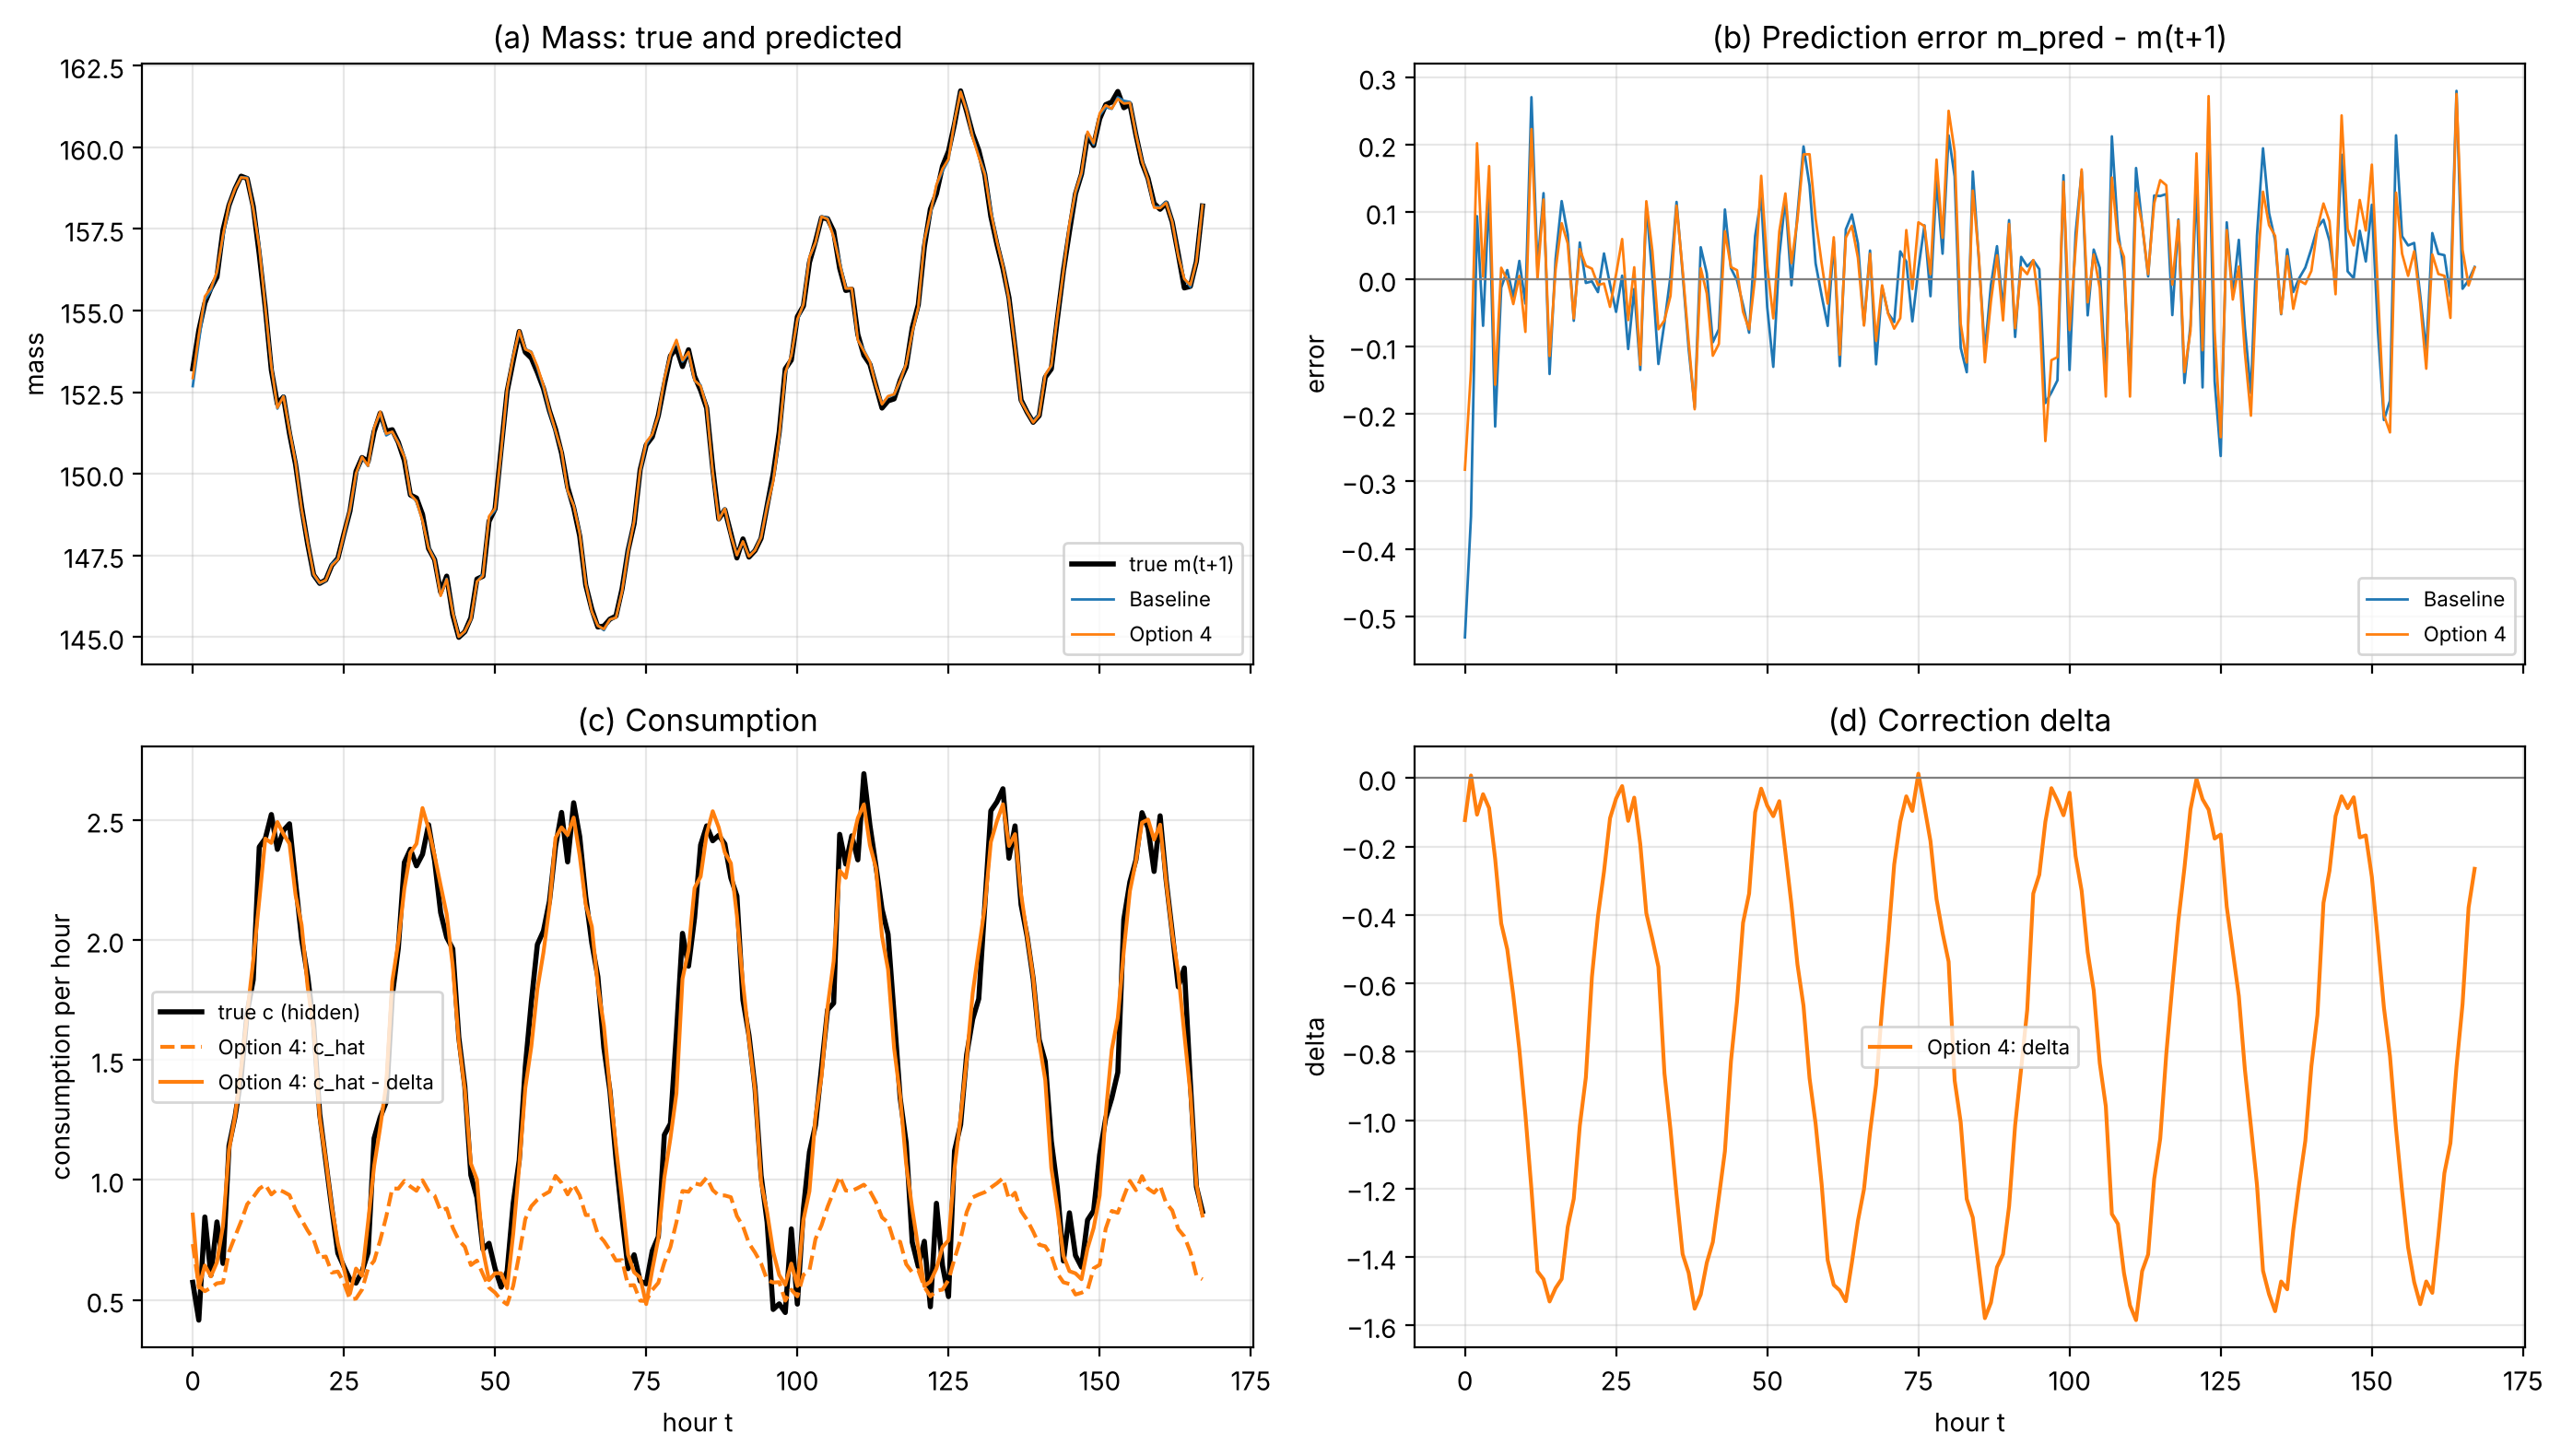

panels: ['(a) Mass: true and predicted', '(b) Prediction error m_pred - m(t+1)', '(c) Consumption', '(d) Correction delta']


In [22]:
def plot_comparison(results, data, seq=0, hours=168):
    """Four panels for one test sequence: mass, error, consumption, delta.

    results: dict label -> run result; models with c_hat appear in panels (c) and (d).
    data: the bundle whose test split was predicted. Returns the figure.
    """
    t = np.arange(hours)
    y = np.asarray(data["Y_te"][seq, :hours])
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    (ax_m, ax_e), (ax_c, ax_d) = axes
    ax_m.plot(t, y, color="black", lw=2, label="true m(t+1)")
    ax_c.plot(t, np.asarray(data["C_te"][seq, :hours]), color="black", lw=2, label="true c (hidden)")
    for i, (label, res) in enumerate(results.items()):
        pred = res["test_m_pred"][seq, :hours]
        ax_m.plot(t, pred, color=f"C{i}", lw=1, label=label)
        ax_e.plot(t, pred - y, color=f"C{i}", lw=1, label=label)
        if "test_c_hat" in res:
            c_hat, delta = res["test_c_hat"][seq, :hours], res["test_delta"][seq, :hours]
            ax_c.plot(t, c_hat, color=f"C{i}", ls="--", label=f"{label}: c_hat")
            ax_c.plot(t, c_hat - delta, color=f"C{i}", label=f"{label}: c_hat - delta")
            ax_d.plot(t, delta, color=f"C{i}", label=f"{label}: delta")
    ax_e.axhline(0, color="grey", lw=0.8)
    ax_d.axhline(0, color="grey", lw=0.8)
    titles = ["(a) Mass: true and predicted", "(b) Prediction error m_pred - m(t+1)",
              "(c) Consumption", "(d) Correction delta"]
    ylabels = ["mass", "error", "consumption per hour", "delta"]
    for ax, title, ylabel in zip(axes.flat, titles, ylabels):
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    for ax in axes[1]:
        ax.set_xlabel("hour t")
    plt.tight_layout()
    plt.show()
    return fig


fig_cmp = plot_comparison({"Baseline": RESULTS["baseline"], "Option 4": RESULTS["opt4"]}, DATA)
print("panels:", [ax.get_title() for ax in fig_cmp.axes])
assert len(fig_cmp.axes) == 4, "four panels expected"
assert all(ax.get_title() and ax.get_legend() for ax in fig_cmp.axes), "every panel needs a title and a legend"

### Interpretation of the main comparison

**Accuracy.** Both trained models are far better than the naive references (persistence 0.758, constant consumption 0.482). Option 4 reaches a test MSE of 0.01015 against 0.01427 for the baseline, about 29 % lower, and an MAE of 0.0804 against 0.0909. The consumption noise has standard deviation 0.1, so no model can go below an MSE of about 0.01: Option 4 is essentially at that floor. The loss curves show the other difference: Option 4 starts at a training loss of 0.510 (it only has to learn a term of order 1), the baseline at 212.976 (it has to learn the whole mass, of order 150), and the baseline's validation loss keeps jumping between epochs. Best-epoch selection removes that luck from the comparison.

**Physical consistency.** The assignment expects a non-zero physical error for the baseline. Here it is non-zero but tiny: 0.00006, from negative implied consumption on 0.027 % of the test steps. This is much smaller than in the assignment's reference because, with this data, the true consumption (0.15–3.01) is far from zero compared with the baseline's error (MAE 0.0909): a violation needs an error that crosses the boundary at a step where `c` is small. The baseline's result is *measured on this test set*; nothing in the model prevents it, and sections 8E.4–8E.5 show where it grows.

Option 4 has physical error 0 and no violations on this test set. The assignment expects "generally non-zero" for Option 4, because `δ` has no positivity constraint. Here `δ` is negative on average (−0.789), which raises the implied consumption `ĉ − δ` instead of lowering it, and `ĉ − δ` follows the true `c` with MAE 0.0804, so it never gets near zero. This zero is measured, not guaranteed.

**Cost.** Training times are similar (63.3 s and 68.0 s in this run; they vary by a few seconds between runs): the structure costs nothing measurable.

**What Option 4 learned: `ĉ` and `δ` are not identified.** The MAE of `ĉ` against the true `c` is 0.7964, while the MAE of `ĉ − δ` is 0.0804. Panels (c)–(d) show why: `ĉ` is a flattened copy of `c` (between about 0.5 and 1.0), and `δ` (mean −0.789, maximum `│δ│` 1.78) is not a constant offset but follows the daily cycle and supplies the rest. Only `ĉ − δ` enters the prediction, so the loss has no reason to prefer one split over the other. The recovered consumption of this model is therefore `ĉ − δ`, not `ĉ`, and the size of `δ` does not show a missing term in the physics: the balance here is exact. Section 8E.1 tests whether a penalty on `δ` fixes this.

<a id='8E'></a>
## 8E. Extended experiments

The main comparison answers the assignment's question on this data. Phase A's choice of Option 4 rested on further claims, and each experiment below tests one of them:

| | Question | Experiment |
| --- | --- | --- |
| 8E.1 | Does `δ` stay small, and is `ĉ` the real consumption? | A penalty `μ · mean(δ²)`, with `μ` chosen on validation |
| 8E.2 | What do the correction and the baseline's output scaling change? | Ablations: Option 3 (no `δ`), unscaled baseline |
| 8E.3 | Are the differences larger than training luck? | Three seeds |
| 8E.4 | Does the physics help more when data is scarce? | 25–300 training sequences |
| 8E.5 | What happens outside the training conditions? | A test set 15 °C colder |
| 8E.6 | Does the correction pay off when the equation is incomplete? | An unmetered inflow |

Every run uses the settings of the main runs (FR4.1); only the factor named changes. Interpretations are written after the numbers and cite them.

### 8E.1 A penalty on δ

Only `ĉ − δ` enters the prediction, so the plain MSE cannot tell a larger `ĉ` from a more negative `δ`. Adding `μ · mean(δ²)` to the loss states in the objective what the plan assumed: the correction should stay small unless the data needs it.

Option 4 is retrained with `μ ∈ {0.01, 0.1, 1.0}`; the main run is `μ = 0`. **Selection rule (validation only):** among the four candidates whose best validation MSE is within 2 % of the lowest, take the largest `μ`. The chosen model is **Option 4-R**. The validation MSE has no penalty term, so the candidates are compared on the same quantity. Neither the test set nor `C` plays any part in the choice.

opt4_mu0.01_s112358: computed (training time 72.4 s)


opt4_mu0.1_s112358: computed (training time 67.9 s)


opt4_mu1.0_s112358: computed (training time 67.8 s)
Rule: largest mu with validation MSE <= 1.02 x lowest = 0.010104. Chosen: mu = 1.0

              val MSE    test MSE  phys. error  violations    mean |d|  mean delta   MAE c_hat  MAE c-delta
mu = 0.0      0.00992     0.01015      0.00000      0.000%      0.7903     -0.7890      0.7964       0.0804
mu = 0.01     0.00994     0.01015      0.00000      0.000%      0.0217     -0.0031      0.0844       0.0804
mu = 0.1      0.00992     0.01015      0.00000      0.000%      0.0059     -0.0010      0.0808       0.0804
mu = 1.0      0.00991     0.01013      0.00000      0.000%      0.0018      0.0004      0.0803       0.0803


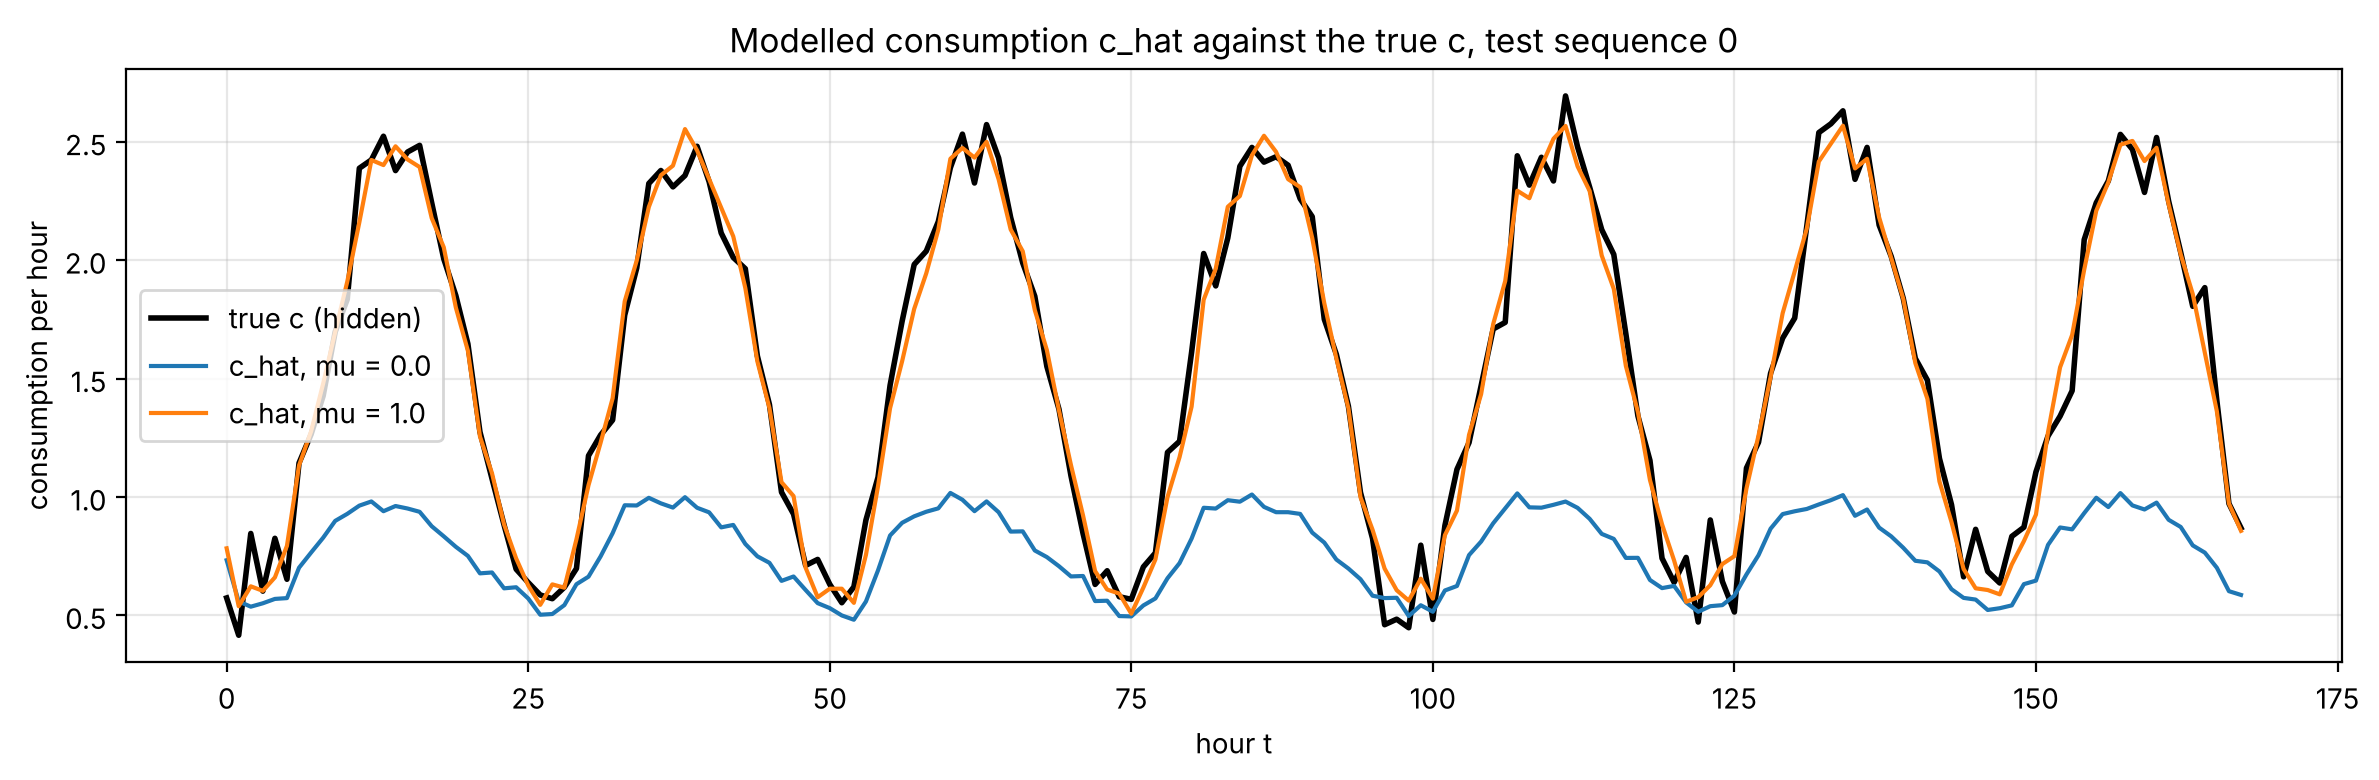

mean |delta| for mu = [0.0, 0.01, 0.1, 1.0] : [0.7903 0.0217 0.0059 0.0018]


In [23]:
MU_RESULTS = {0.0: RESULTS["opt4"]}
for mu in CONFIG["mu_grid"]:
    MU_RESULTS[mu] = run_cached(f"opt4_mu{mu}_s112358", kind="option4", data=DATA, mu=mu,
                                eval_sets={"shift": DATA_SHIFT})


def select_mu(val_mse, tolerance=0.02):
    """Largest mu whose validation MSE is within `tolerance` (relative) of the lowest.

    val_mse: dict mu -> best validation MSE (validation set only). Output: (chosen mu, threshold).
    """
    threshold = min(val_mse.values()) * (1 + tolerance)
    return max(mu for mu, v in val_mse.items() if v <= threshold), threshold


val_mse_by_mu = {mu: float(res["val_loss"].min()) for mu, res in MU_RESULTS.items()}
MU_CHOSEN, mu_threshold = select_mu(val_mse_by_mu)
RESULTS["opt4R"] = MU_RESULTS[MU_CHOSEN]
print(f"Rule: largest mu with validation MSE <= 1.02 x lowest = {mu_threshold:.6f}. Chosen: mu = {MU_CHOSEN}"
      + (" (Option 4-R is the main Option 4 model)" if MU_CHOSEN == 0.0 else ""))
print()

mu_rows = [(f"mu = {mu}", {"val": val_mse_by_mu[mu], **evaluate(res, DATA)}) for mu, res in MU_RESULTS.items()]
print_table(mu_rows, [("val", "val MSE", ".5f"), ("mse", "test MSE", ".5f"), ("phys", "phys. error", ".5f"),
                      ("viol", "violations", ".3%"), ("mean_abs_delta", "mean |d|", ".4f"),
                      ("mean_delta", "mean delta", ".4f"), ("mae_c", "MAE c_hat", ".4f"),
                      ("mae_eff", "MAE c-delta", ".4f")])

seq, hours = 0, 168
t = np.arange(hours)
plot_mus = [0.0] if MU_CHOSEN == 0.0 else [0.0, MU_CHOSEN]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t, np.asarray(DATA["C_te"][seq, :hours]), color="black", lw=2, label="true c (hidden)")
for i, mu in enumerate(plot_mus):
    ax.plot(t, MU_RESULTS[mu]["test_c_hat"][seq, :hours], color=f"C{i}", label=f"c_hat, mu = {mu}")
ax.set_title(f"Modelled consumption c_hat against the true c, test sequence {seq}")
ax.set_xlabel("hour t")
ax.set_ylabel("consumption per hour")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

mean_abs_d = [evaluate(MU_RESULTS[mu], DATA)["mean_abs_delta"] for mu in sorted(MU_RESULTS)]
print("mean |delta| for mu =", sorted(MU_RESULTS), ":", np.round(mean_abs_d, 4))
assert all(a >= b for a, b in zip(mean_abs_d, mean_abs_d[1:])), "mean |delta| must not increase as mu grows"
assert MU_CHOSEN in MU_RESULTS, "the chosen mu must be one of the four candidates"

**Interpretation.** All four candidates fit equally well: validation MSE between 0.00991 and 0.00994, all within 2 % of the lowest (threshold 0.010104). The rule therefore picks the largest `μ`, 1.0, as Option 4-R. The test MSE does not move (0.01013–0.01015), and the physical error is 0 for every `μ`.

What changes is the split between the two terms. Mean `│δ│` falls from 0.7903 (`μ = 0`) to 0.0217, 0.0059 and 0.0018, and the MAE of `ĉ` against the true `c` falls from 0.7964 to 0.0803, the same as the MAE of `ĉ − δ`. With the penalty, `ĉ` alone is the consumption (see the plot), and `δ` is almost zero, which is what an exact balance should give. So the identifiability problem of the main model costs nothing in accuracy, and a penalty that uses neither the test set nor `C` resolves it. Two caveats: the prototype of `architecture.md` §7 (seed 42) chose `μ = 0.1`; here `μ = 1.0` also passes the 2 % rule, and larger values were not tried. And the accuracy of `ĉ` is checked with `C` only after training, as a diagnostic.

### 8E.2 Ablations

Two runs that each remove one design decision, everything else as in the main runs:

- **Option 3** (`δ` removed): the hard constraint alone. On data that obeys the balance exactly, this measures what the extra flexibility of Option 4 costs or gains.
- **Baseline without output scaling** (`m̂ = output`, as the template's stub reads literally): shows why the main baseline maps its output with the training statistics.

In [24]:
RESULTS["opt3"] = run_cached("opt3_s112358", kind="option3", data=DATA, eval_sets={"shift": DATA_SHIFT})
RESULTS["baseline_raw"] = run_cached("baseline_raw_s112358", kind="baseline", data=DATA, output_scaling=False,
                                     eval_sets={"shift": DATA_SHIFT})
print()

ablation_rows = [("Baseline", metrics_of("baseline")), ("Baseline, unscaled output", metrics_of("baseline_raw")),
                 ("Option 4", metrics_of("opt4")), (f"Option 4-R (mu = {MU_CHOSEN})", metrics_of("opt4R")),
                 ("Option 3 (no delta)", metrics_of("opt3"))]
print_table(ablation_rows, MAIN_COLUMNS + [("best_epoch", "best epoch", "d"), ("mean_abs_delta", "mean |d|", ".4f"),
                                           ("mae_c", "MAE c_hat", ".4f")])
opt3_phys = metrics_of("opt3")["phys"]
print(f"\nOption 3 physical error: {opt3_phys!r}")
assert opt3_phys == 0.0, "Option 3's physical error must be exactly 0"

opt3_s112358: computed (training time 70.0 s)


baseline_raw_s112358: computed (training time 68.4 s)

                                  MSE         MAE  phys. error  violations    time (s)  best epoch    mean |d|   MAE c_hat
Baseline                      0.01427      0.0909      0.00006      0.027%        63.3         253                        
Baseline, unscaled output   282.10132     12.4226      6.56268     50.429%        68.4         291                        
Option 4                      0.01015      0.0804      0.00000      0.000%        68.0         271      0.7903      0.7964
Option 4-R (mu = 1.0)         0.01013      0.0803      0.00000      0.000%        67.8         257      0.0018      0.0803
Option 3 (no delta)           0.01015      0.0803      0.00000      0.000%        70.0         297      0.0000      0.0803

Option 3 physical error: 0.0


**Interpretation.**

- **Option 3 vs Option 4.** Option 3 reaches the same accuracy as Option 4 (test MSE 0.01015 for both, MAE 0.0803 against 0.0804), with a physical error of exactly 0.0. Option 3's zero is guaranteed by its architecture, not just measured. On data that obeys the balance exactly, the correction `δ` buys nothing in accuracy. Its only effect is the identifiability problem of the main model, which the penalty of 8E.1 removes (Option 4-R: mean `│δ│` 0.0018, MAE of `ĉ` 0.0803). Whether the small difference in MSE between Option 4 and Option 3 is larger than training luck is checked against the seed-to-seed spread in 8E.3.
- **Unscaled baseline.** Without the output scaling, the baseline ends at a test MSE of 282.10 (MAE 12.42), a physical error of 6.56 and violations on 50.429 % of the steps. Its best epoch is 291 of 300, so it was still improving when training stopped. The network must move its output from about 0 to about 156 before it can learn anything finer, and 300 epochs are not enough. Its errors are much larger than the consumption itself, so the sign of the implied consumption is close to random. This is an under-trained model, not a property of direct prediction: with the scaling, the same architecture reaches 0.01427. Without it, the main comparison would measure output scaling instead of physics.

### 8E.3 Repeated seeds

The data stays fixed; the seed changes the initialization and the order of the mini-batches. The baseline and Option 4 are retrained with seeds 112359 and 112360 (three runs each, with the main 112358). The table shows mean ± standard deviation over the three runs (sample standard deviation, `ddof=1`). Three seeds give a rough idea of the spread, not a significance test.

In [25]:
SEED_RESULTS = {"baseline": [RESULTS["baseline"]], "opt4": [RESULTS["opt4"]]}
for seed in CONFIG["seeds"][1:]:
    for label, kind in (("baseline", "baseline"), ("opt4", "option4")):
        SEED_RESULTS[label].append(run_cached(f"{label}_s{seed}", kind=kind, data=DATA, seed=seed,
                                              eval_sets={"shift": DATA_SHIFT}))
print()

SEED_METRICS = {label: [evaluate(res, DATA) for res in runs] for label, runs in SEED_RESULTS.items()}
seed_rows = []
for label, name in (("baseline", "Baseline"), ("opt4", "Option 4")):
    row = {}
    for key in ("mse", "mae", "phys", "viol"):
        values = np.array([mt[key] for mt in SEED_METRICS[label]])
        row[key] = f"{values.mean():.5f} ± {values.std(ddof=1):.5f}" if key != "viol" else \
                   f"{values.mean():.3%} ± {values.std(ddof=1):.3%}"
    seed_rows.append((f"{name} (3 seeds)", row))
print_table(seed_rows, [("mse", "test MSE", "s"), ("mae", "MAE", "s"), ("phys", "physical error", "s"),
                        ("viol", "violation rate", "s")])

for label in ("baseline", "opt4"):
    print(f"{label:8s} test MSE per seed:", [round(mt["mse"], 5) for mt in SEED_METRICS[label]])
mse_seeds = {label: np.array([mt["mse"] for mt in SEED_METRICS[label]]) for label in SEED_METRICS}
gap = mse_seeds["baseline"].mean() - mse_seeds["opt4"].mean()
print(f"\nGap in mean test MSE (baseline - Option 4): {gap:.5f}; "
      f"std baseline {mse_seeds['baseline'].std(ddof=1):.5f}, std Option 4 {mse_seeds['opt4'].std(ddof=1):.5f}")
print(f"Worst Option 4 seed {mse_seeds['opt4'].max():.5f} vs best baseline seed {mse_seeds['baseline'].min():.5f}")
diff_43 = metrics_of("opt4")["mse"] - metrics_of("opt3")["mse"]
print(f"For 8E.2: Option 4 - Option 3 test MSE = {diff_43:+.5f}; Option 4 seed-to-seed std = {mse_seeds['opt4'].std(ddof=1):.5f}")

assert all(len(runs) == 3 for runs in SEED_RESULTS.values()), "three runs per model expected"

baseline_s112359: computed (training time 60.9 s)


opt4_s112359: computed (training time 71.0 s)


baseline_s112360: computed (training time 65.5 s)


opt4_s112360: computed (training time 68.0 s)

                      test MSE         MAE  physical error  violation rate
Baseline (3 seeds)  0.01454 ± 0.00024  0.09371 ± 0.00258  0.00003 ± 0.00003  0.013% ± 0.012%
Option 4 (3 seeds)  0.01015 ± 0.00001  0.08037 ± 0.00000  0.00000 ± 0.00000  0.000% ± 0.000%
baseline test MSE per seed: [0.01427, 0.01471, 0.01463]
opt4     test MSE per seed: [0.01015, 0.01016, 0.01015]

Gap in mean test MSE (baseline - Option 4): 0.00438; std baseline 0.00024, std Option 4 0.00001
Worst Option 4 seed 0.01016 vs best baseline seed 0.01427
For 8E.2: Option 4 - Option 3 test MSE = +0.00000; Option 4 seed-to-seed std = 0.00001


**Interpretation.** Over three seeds the baseline has a test MSE of 0.01454 ± 0.00024 (0.01427, 0.01471, 0.01463) and Option 4 0.01015 ± 0.00001. The gap between the means, 0.00438, is about 18 times the baseline's standard deviation, and the worst Option 4 seed (0.01016) is below the best baseline seed (0.01427). On this data, Option 4's accuracy advantage is larger than training luck. Three seeds give a rough spread, not a significance test.

Option 4 hardly depends on the seed: with the balance built in, there is little left for the initialization and batch order to change. The baseline's physical error (0.00003 ± 0.00003) and violation rate (0.013 % ± 0.012 %) vary from seed to seed and are of the size of their own spread: they are rare events, not a stable property of a trained baseline.

**Completing 8E.2:** Option 4 and Option 3 differ in test MSE by +0.00000, less than Option 4's seed-to-seed standard deviation (0.00001). There is no measurable difference in accuracy between the two on data with an exact balance.

### 8E.4 Low-data ablation

The claim of Phase A Discussion 3: with the balance built in, the network only has to learn the small hidden term, so it should need fewer sequences. Both models are retrained on the first `n_train ∈ {25, 50, 100, 200}` training sequences (300 is the main run). Validation set, test set, epochs, batch size and every other setting stay fixed. Normalization statistics are recomputed from the sequences actually used. With the same epochs and batch size, fewer sequences also mean fewer updates (25 sequences: one batch per epoch, 300 updates in total, instead of 3,000).

baseline_n25_s112358: computed (training time 9.7 s)


opt4_n25_s112358: computed (training time 9.3 s)


baseline_n50_s112358: computed (training time 17.3 s)


opt4_n50_s112358: computed (training time 17.4 s)


baseline_n100_s112358: computed (training time 27.5 s)


opt4_n100_s112358: computed (training time 32.8 s)


baseline_n200_s112358: computed (training time 46.0 s)


opt4_n200_s112358: computed (training time 48.9 s)

               MSE baseline  MSE option 4   ratio b/4  viol. base  viol. opt 4  phys. base  phys. opt 4
n_train = 25        6.25615       0.01379       453.5      5.812%       0.000%     0.32653      0.00000
n_train = 50        0.25049       0.01108        22.6      0.617%       0.000%     0.01862      0.00000
n_train = 100       0.04658       0.01040         4.5      0.156%       0.000%     0.00192      0.00000
n_train = 200       0.01973       0.01025         1.9      0.013%       0.000%     0.00003      0.00000
n_train = 300       0.01427       0.01015         1.4      0.027%       0.000%     0.00006      0.00000


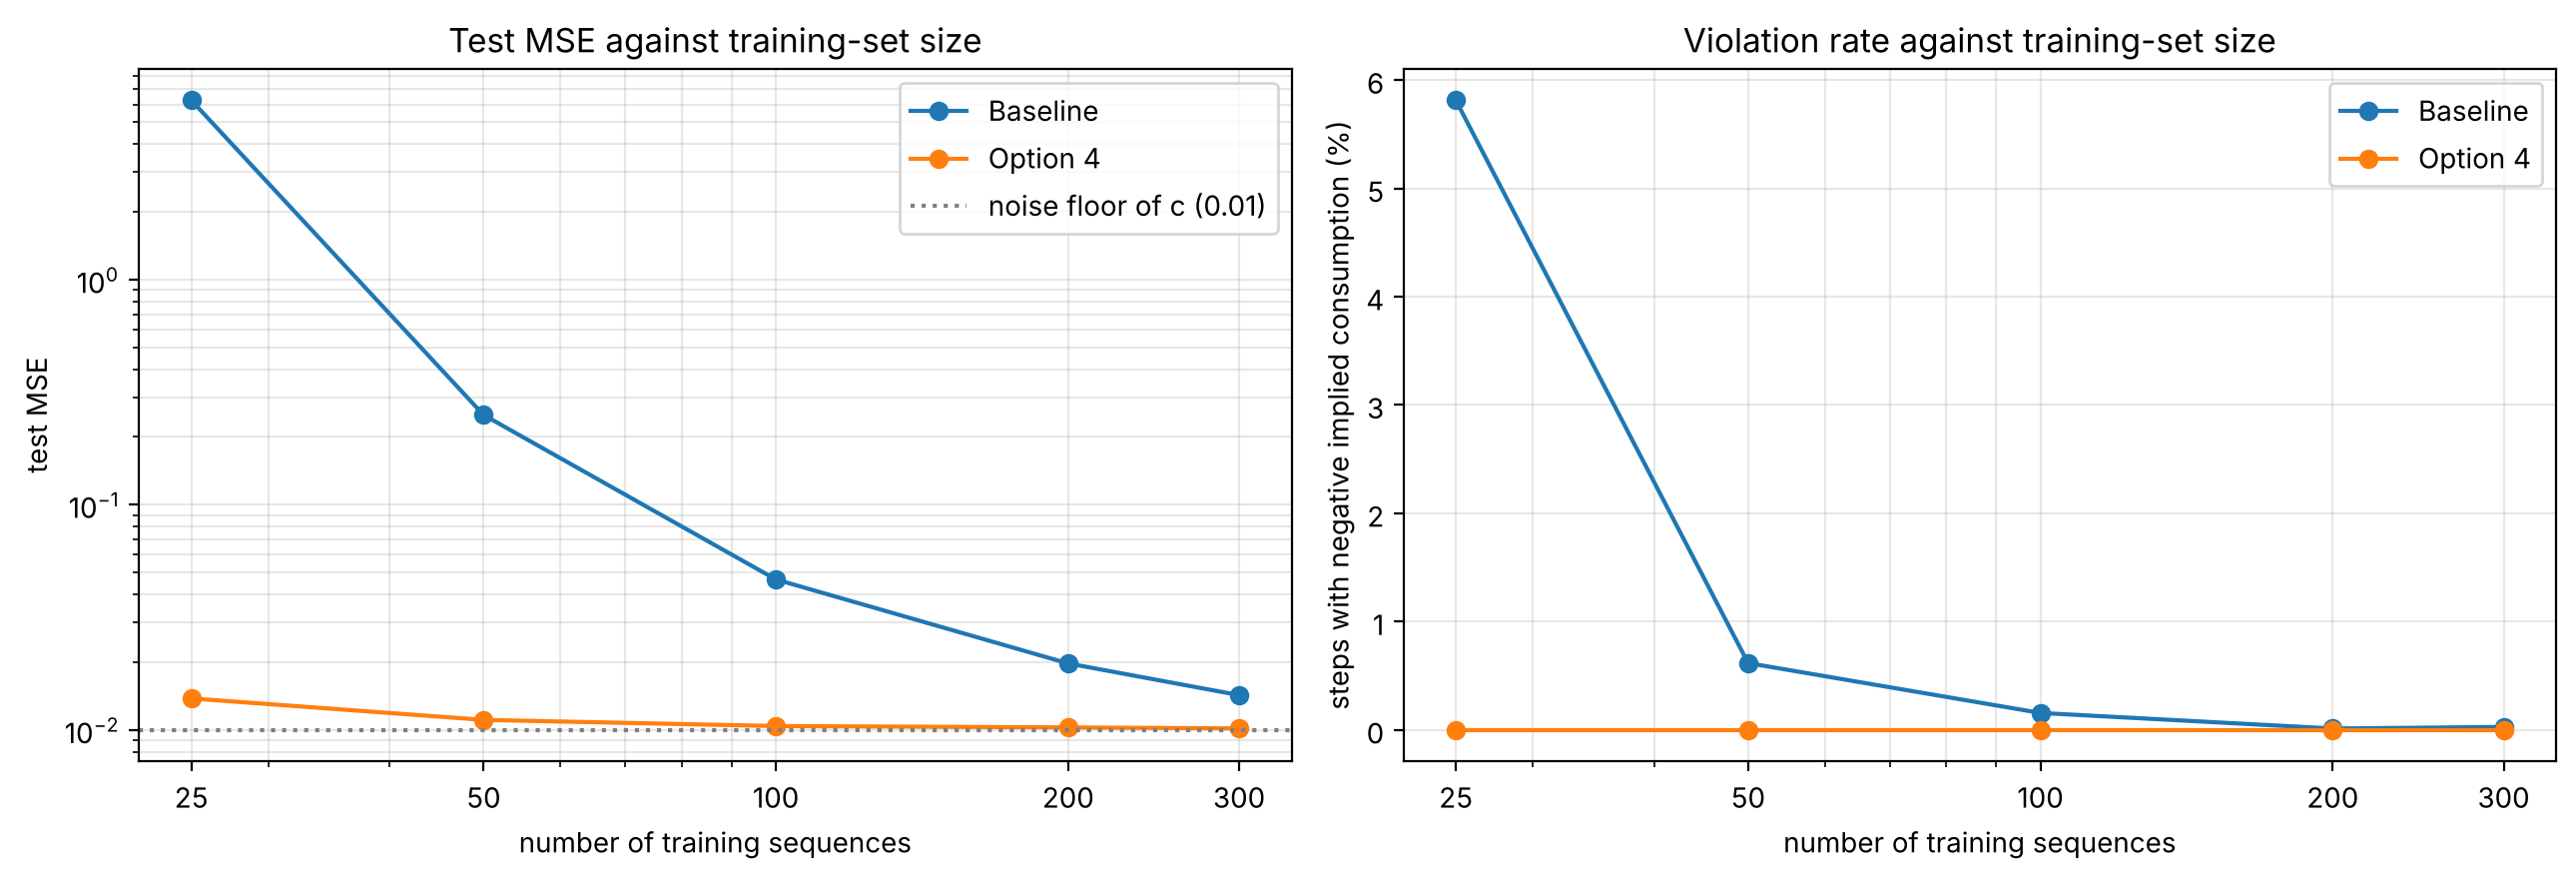

MSE ratio baseline / Option 4: 453.5 at 25 sequences, 1.4 at 300


In [26]:
LOW_RESULTS = {"baseline": {300: RESULTS["baseline"]}, "opt4": {300: RESULTS["opt4"]}}
LOW_DATA = {300: DATA}
for n in CONFIG["n_train_grid"]:
    LOW_DATA[n] = make_dataset(data_key, n_train=n, tag=f"n{n}")
    for label, kind in (("baseline", "baseline"), ("opt4", "option4")):
        LOW_RESULTS[label][n] = run_cached(f"{label}_n{n}_s112358", kind=kind, data=LOW_DATA[n])
print()

sizes = sorted(LOW_DATA)
LOW_METRICS = {label: {n: evaluate(LOW_RESULTS[label][n], LOW_DATA[n]) for n in sizes} for label in LOW_RESULTS}
low_rows = []
for n in sizes:
    b, o = LOW_METRICS["baseline"][n], LOW_METRICS["opt4"][n]
    low_rows.append((f"n_train = {n}", {"mse_b": b["mse"], "mse_4": o["mse"], "ratio": b["mse"] / o["mse"],
                                        "viol_b": b["viol"], "viol_4": o["viol"], "phys_b": b["phys"], "phys_4": o["phys"]}))
print_table(low_rows, [("mse_b", "MSE baseline", ".5f"), ("mse_4", "MSE option 4", ".5f"), ("ratio", "ratio b/4", ".1f"),
                       ("viol_b", "viol. base", ".3%"), ("viol_4", "viol. opt 4", ".3%"),
                       ("phys_b", "phys. base", ".5f"), ("phys_4", "phys. opt 4", ".5f")])

fig, (ax_mse, ax_v) = plt.subplots(1, 2, figsize=(13, 4.5))
for i, (label, name) in enumerate((("baseline", "Baseline"), ("opt4", "Option 4"))):
    ax_mse.plot(sizes, [LOW_METRICS[label][n]["mse"] for n in sizes], "o-", color=f"C{i}", label=name)
    ax_v.plot(sizes, [LOW_METRICS[label][n]["viol"] * 100 for n in sizes], "o-", color=f"C{i}", label=name)
ax_mse.axhline(0.01, color="grey", ls=":", label="noise floor of c (0.01)")
ax_mse.set_xscale("log")
ax_mse.set_yscale("log")
ax_mse.set_title("Test MSE against training-set size")
ax_mse.set_ylabel("test MSE")
ax_v.set_xscale("log")
ax_v.set_title("Violation rate against training-set size")
ax_v.set_ylabel("steps with negative implied consumption (%)")
for ax in (ax_mse, ax_v):
    ax.set_xticks(sizes)
    ax.set_xticklabels(sizes)
    ax.xaxis.set_minor_formatter(plt.NullFormatter())   # only the five sizes as labels
    ax.set_xlabel("number of training sequences")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
plt.tight_layout()
plt.show()

ratio_25, ratio_300 = low_rows[0][1]["ratio"], low_rows[-1][1]["ratio"]
print(f"MSE ratio baseline / Option 4: {ratio_25:.1f} at 25 sequences, {ratio_300:.1f} at 300")
assert all(len(LOW_METRICS[label]) == 5 for label in LOW_METRICS), "5 points per model expected"
assert ratio_25 > ratio_300, "the advantage of Option 4 must be larger at 25 sequences than at 300"

**Interpretation.** Option 4's advantage grows as the data shrinks. The ratio of test MSEs (baseline / Option 4) is 1.4 with 300 sequences, 1.9 with 200, 4.5 with 100, 22.6 with 50 and 453.5 with 25. Option 4 stays close to the noise floor at every size (0.01379 with 25 sequences, 0.01015 with 300). The baseline goes from 0.01427 to 6.25615. Option 4 trained on 25 sequences (MSE 0.01379) is more accurate than the baseline trained on 300 (0.01427).

The physical side follows the same pattern. The baseline's violation rate rises from 0.027 % at 300 sequences to 0.617 % at 50 and 5.812 % at 25 (physical error 0.32653). Option 4 has none at any size on this test set.

This is the inductive bias of Phase A Discussion 3, measured directly: the balance supplies the large, easy part of the answer, so the network only needs enough data to learn the small hidden term from temperature and time. Two caveats. Fewer sequences also mean fewer updates (300 instead of 3,000 at 25 sequences), as the assignment's design implies, so this measures data and updates together, for both models alike. And each point is one seed; the gaps at 25–100 sequences are much larger than the seed spread of 8E.3, but that spread was measured at 300 sequences only. The prototype of `architecture.md` §7 (seed 42, no clipping) gave a baseline MSE of about 1.1 at 25 sequences; the direction is the same, the size larger here.

### 8E.5 Distribution shift: a cold spell

No new training. The models trained on `DATA` already stored their predictions on `DATA_SHIFT`: the same test sequences, with the temperature 15 °C lower, normalized with the original training statistics. The true consumption follows the temperature down and is clipped at zero on many steps, which is exactly the physical boundary a violation crosses. Temperatures this low never occur in training, so every model extrapolates.

Share of shifted test steps with true c = 0: 14.4%

                       MSE in-dist  MSE shifted     x worse    phys. in  phys. shift    viol. in  viol. shift
Baseline                   0.01427   16748.3900     1173925     0.00006      0.00052      0.027%       0.400%
Option 4                   0.01015       0.1648          16     0.00000      0.00000      0.000%       0.000%
Option 4-R (mu = 1.0)      0.01013       0.1376          14     0.00000      0.00000      0.000%       0.000%
Option 3                   0.01015       0.1331          13     0.00000      0.00000      0.000%       0.000%

Shifted set: the baseline predicts less water than the true mass on 87.9% of the steps


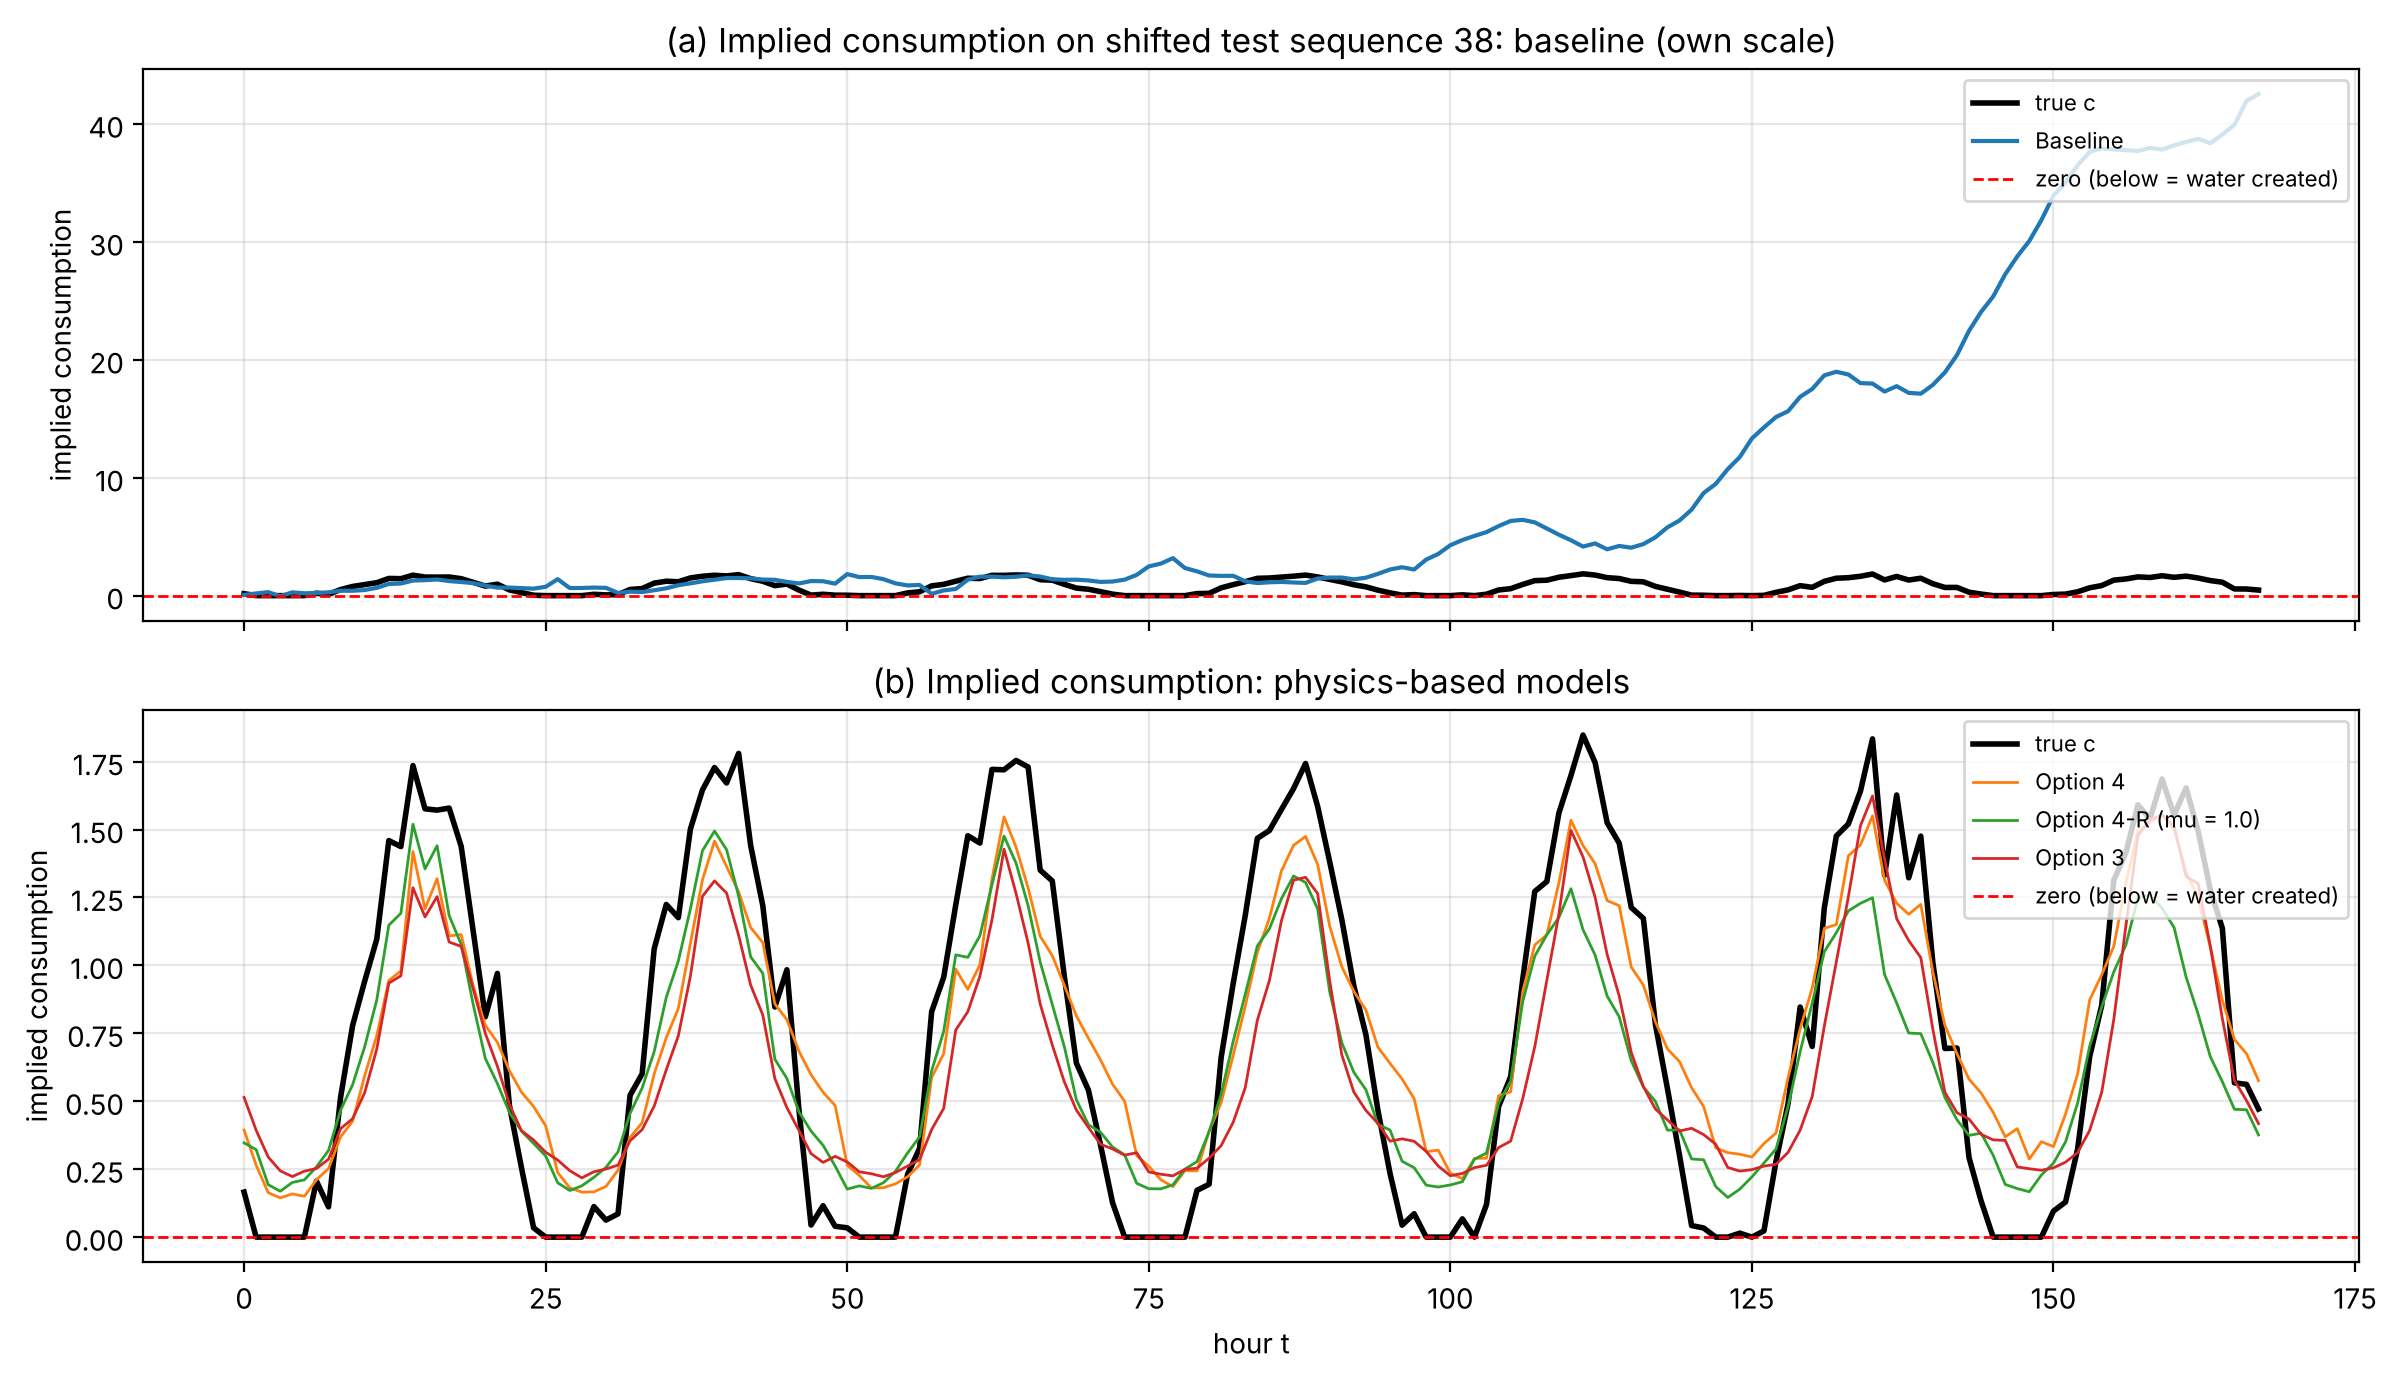

Option 3 physical error on the shifted set: 0.0


In [27]:
share_c0 = float(np.mean(np.asarray(DATA_SHIFT["C_te"]) == 0))
print(f"Share of shifted test steps with true c = 0: {share_c0:.1%}\n")

shift_models = [("Baseline", "baseline"), ("Option 4", "opt4"), (f"Option 4-R (mu = {MU_CHOSEN})", "opt4R"),
                ("Option 3", "opt3")]
shift_rows = []
for name, label in shift_models:
    ind, sh = evaluate(RESULTS[label], DATA), evaluate(RESULTS[label], DATA_SHIFT, prefix="shift")
    shift_rows.append((name, {"mse": ind["mse"], "mse_s": sh["mse"], "ratio": sh["mse"] / ind["mse"],
                              "phys": ind["phys"], "phys_s": sh["phys"], "viol": ind["viol"], "viol_s": sh["viol"]}))
print_table(shift_rows, [("mse", "MSE in-dist", ".5f"), ("mse_s", "MSE shifted", ".4f"), ("ratio", "x worse", ".0f"),
                         ("phys", "phys. in", ".5f"), ("phys_s", "phys. shift", ".5f"),
                         ("viol", "viol. in", ".3%"), ("viol_s", "viol. shift", ".3%")])

below = float(np.mean(RESULTS["baseline"]["shift_m_pred"] < np.asarray(DATA_SHIFT["Y_te"])))
print(f"\nShifted set: the baseline predicts less water than the true mass on {below:.1%} of the steps")

# The test sequence with the most steps at c = 0, first week.
seq = int(np.argmax(np.mean(np.asarray(DATA_SHIFT["C_te"]) == 0, axis=1)))
hours = 168
t = np.arange(hours)
x_s = np.asarray(DATA_SHIFT["X_te"][seq, :hours])
b_s = (x_s[:, 0] + x_s[:, 1]) - x_s[:, 2]
c_true_s = np.asarray(DATA_SHIFT["C_te"][seq, :hours])
fig, (ax_b, ax_p) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax_b.plot(t, c_true_s, color="black", lw=2, label="true c")
ax_b.plot(t, b_s - RESULTS["baseline"]["shift_m_pred"][seq, :hours], color="C0", label="Baseline")
ax_b.set_title(f"(a) Implied consumption on shifted test sequence {seq}: baseline (own scale)")
ax_p.plot(t, c_true_s, color="black", lw=2, label="true c")
for i, (name, label) in enumerate(shift_models[1:], start=1):
    ax_p.plot(t, b_s - RESULTS[label]["shift_m_pred"][seq, :hours], color=f"C{i}", lw=1, label=name)
ax_p.set_title("(b) Implied consumption: physics-based models")
ax_p.set_xlabel("hour t")
for ax in (ax_b, ax_p):
    ax.axhline(0, color="red", lw=1, ls="--", label="zero (below = water created)")
    ax.set_ylabel("implied consumption")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

opt3_shift_phys = evaluate(RESULTS["opt3"], DATA_SHIFT, prefix="shift")["phys"]
print(f"Option 3 physical error on the shifted set: {opt3_shift_phys!r}")
assert share_c0 > 0.05, "the shifted set must have c = 0 on more than 5 % of the steps"
assert opt3_shift_phys == 0.0, "Option 3's physical error must be exactly 0 on the shifted set"

**Interpretation.** The cold spell puts the true consumption at zero on 14.4 % of the test steps, and its temperatures lie outside anything seen in training.

- **Baseline.** Its test MSE goes from 0.01427 to 16748.39 (about 1.2 million times worse). Panel (a) shows how: the predicted mass drifts away from the true one over the sequence, so the implied consumption climbs to about 40 on this sequence. The network has to extrapolate the whole mass from inputs it has never seen. Its violations rise from 0.027 % to 0.400 % of the steps (physical error 0.00006 → 0.00052). This is fewer than the size of its errors would suggest, because on 87.9 % of the shifted steps it predicts less water than there is, which makes the implied consumption too large rather than negative.
- **Physics-based models.** Their MSE grows 13–16 times (0.1331 for Option 3, 0.1376 for Option 4-R, 0.1648 for Option 4), from about 0.01. They also extrapolate `ĉ` from unseen temperatures: panel (b) shows that they do not follow the true `c` down to zero (their implied consumption stays near 0.2 on cold nights) and they underestimate the peaks. But the prediction stays anchored to `m + r − q`, so the error is limited to the error in the hidden term.
- **Physical error.** Option 3 has exactly 0.0 on the shifted set, as guaranteed. Option 4 and Option 4-R also have 0 here. This differs from the prototype of `architecture.md` §7, where Option 4 violated on about 0.1 % of the steps. For Option 4 it is a measurement on this set, not a guarantee, because `δ` is unconstrained.

The degradation follows the amount of structure: Option 3 (13×) < Option 4-R (14×) < Option 4 (16×), with the baseline orders of magnitude worse. This is one seed and one kind of shift.

### 8E.6 Incomplete physics: an unmetered inflow

The scenario Option 4 was chosen for. A second dataset, `DATA_INC`, adds an **unmetered inflow** of 1.0 per step to the mass (seepage, runoff, rain on the surface) that no feature shows and the balance equation does not contain: `m(t+1) = m(t) + r(t) − q(t) − c(t) + 1.0`. The net hidden term `c − 1` becomes negative whenever `c < 1` (cool nights), which `ĉ ≥ 0` cannot represent.

Option 3 and Option 4 are trained and tested on it with the standard settings; `DATA_INC` has its own training statistics. The extra row applies the metrics to the **true** next mass: it shows what "physical error" means when the equation is incomplete.

In [28]:
DATA_INC = make_dataset(data_key, unmetered_inflow=CONFIG["unmetered_inflow"], tag="inc")
RESULTS["opt3_inc"] = run_cached("opt3_inc_s112358", kind="option3", data=DATA_INC)
RESULTS["opt4_inc"] = run_cached("opt4_inc_s112358", kind="option4", data=DATA_INC)
c_inc = np.asarray(DATA_INC["C_te"])
print(f"\nShare of test steps with true c < 1 (net hidden term negative): {np.mean(c_inc < 1):.1%}\n")

true_row = evaluate({"test_m_pred": np.asarray(DATA_INC["Y_te"])}, DATA_INC)
inc_rows = [("True next mass (data)", true_row),
            ("Option 3", evaluate(RESULTS["opt3_inc"], DATA_INC)),
            ("Option 4", evaluate(RESULTS["opt4_inc"], DATA_INC))]
print_table(inc_rows, [("mse", "MSE", ".5f"), ("mae", "MAE", ".4f"), ("phys", "phys. error", ".4f"),
                       ("viol", "violations", ".2%"), ("mean_delta", "mean delta", ".4f"),
                       ("mean_abs_delta", "mean |d|", ".4f")])
# Here the effective consumption c_hat - delta should match the true NET hidden term c - 1, not c.
eff_inc = RESULTS["opt4_inc"]["test_c_hat"] - RESULTS["opt4_inc"]["test_delta"]
print(f"\nOption 4: mean of c_hat - delta = {eff_inc.mean():.4f}; mean of the true net term c - 1 = {np.mean(c_inc - 1):.4f}; "
      f"MAE of c_hat - delta against c - 1 = {np.mean(np.abs(eff_inc - (c_inc - 1))):.4f}")
print(f"Option 3: mean c_hat = {RESULTS['opt3_inc']['test_c_hat'].mean():.4f} (cannot go below 0)")

assert true_row["phys"] > 0, "the true data must have a non-zero physical error when the balance is incomplete"

opt3_inc_s112358: computed (training time 74.4 s)


opt4_inc_s112358: computed (training time 67.2 s)

Share of test steps with true c < 1 (net hidden term negative): 28.5%

                              MSE         MAE  phys. error  violations  mean delta    mean |d|
True next mass (data)     0.00000      0.0000       0.0732      28.46%                        
Option 3                  0.03219      0.1307       0.0000       0.00%      0.0000      0.0000
Option 4                  0.01016      0.0804       0.0708      28.58%      0.1569      0.5040

Option 4: mean of c_hat - delta = 0.5988; mean of the true net term c - 1 = 0.5976; MAE of c_hat - delta against c - 1 = 0.0804
Option 3: mean c_hat = 0.6681 (cannot go below 0)


**Interpretation.** With the unmetered inflow, the net hidden term `c − 1` is negative on 28.5 % of the test steps.

- **Fit.** Option 4 fits at the noise floor (MSE 0.01016, MAE 0.0804); Option 3 does not (MSE 0.03219, MAE 0.1307), about three times worse. Option 3 must put every mismatch into `ĉ ≥ 0`, and a net gain of water cannot be represented that way: its `ĉ` has mean 0.6681, while the true net term has mean 0.5976, because it stays above zero where the net term is negative. Option 4's `ĉ − δ` has mean 0.5988 and follows the net term with MAE 0.0804, the same accuracy as on the exact data. The correction is now large (mean `│δ│` 0.5040, mean `δ` 0.1569). As in the main run, `ĉ` and `δ` are not identified separately: `δ` is not the 1.0 of the unmetered inflow, but `ĉ − δ` is right.
- **What "physical error" means here.** The metric assumes the balance is complete. The *true* next mass itself has a physical error of 0.0732, on 28.46 % of the steps, because on those steps the water really does rise by more than `r − q`. Option 4's physical error (0.0708 on 28.58 % of the steps) matches what the data does; Option 3's 0.0000 matches an equation that is wrong for this reservoir. With an incomplete balance, a zero physical error is not a virtue, and a non-zero one is not an error of the model.

This is the situation for which Phase A chose Option 4, and the claim holds: the hard constraint is the best choice when the equation is complete (8E.2, 8E.5), and the correction pays off when it is not. The prototype of `architecture.md` §7 (seed 42, no clipping) gave very similar numbers (Option 3 ≈ 0.031, Option 4 ≈ 0.010, mean `│δ│` ≈ 0.46, physical error ≈ 0.07 on about 28 % of the steps).

<a id='10'></a>
## 9. Reflection questions

Answer using evidence from **your own** experiments — refer to your metrics table and plots, not just general reasoning.

**1. Why can a conventional LSTM violate a physical law, even after being trained to convergence on plenty of data?**

_Notes (from the assistant, for your answer):_

- MSE only measures the distance to the target. A prediction 0.8 above the truth and one 0.8 below get the same loss, even if only one implies negative consumption. The boundary `m(t+1) ≤ m + r − q` appears nowhere in the architecture or the loss (Phase A, Discussion 2).
- Evidence: the main baseline (300 sequences, best epoch on validation) has negative implied consumption on 0.027 % of the test steps, physical error 0.00006 (main table). Over three seeds: 0.013 % ± 0.012 % (8E.3). Rare here, because the true `c` (0.15–3.01) is far from zero compared with the baseline's MAE (0.0909).
- Nothing protects that zero: violations grow to 5.812 % with 25 training sequences (8E.4), to 0.400 % on the cold-spell set where `c = 0` on 14.4 % of steps (8E.5), and to 50.429 % for the under-trained, unscaled baseline (8E.2).
- "Plenty of data" lowers the frequency, but does not change the fact that the model can do it. Option 3's physical error is exactly 0.0, untrained (task 2.3), on the test set (8E.2) and on the shifted set (8E.5), because it comes from the structure, not from the data.

_Your answer:_

*(write here)*

**2. What is the difference between a soft constraint and a hard constraint? If you implemented Option 3 or 4, where would a soft constraint have gone instead, and how would training/evaluation have differed? If you implemented Option 2, reflect on how your choice of `λ` affected the accuracy/conservation trade-off.**

_Notes (from the assistant, for your answer):_

- Hard constraint: part of the architecture, holds for every parameter value and every input (Option 3: physical error 0.0 even untrained and on the shifted set). Soft constraint: a penalty term in the loss, traded against accuracy through `λ`; it is only encouraged, on the training distribution.
- Option 4 sits in between: the balance is hard-wired, but `δ` is unconstrained, so conservation is approximate. Measured 0 on the test and shifted sets (main table, 8E.5), not guaranteed.
- A soft version (Option 2) would have two free heads `(m̂, ĉ)` and the term `λ · (m̂ − m − r + q + ĉ)²` in the loss. Training: a new hyperparameter, chosen with several runs on validation. Evaluation: report the residual of the physics term next to MSE; and `ĉ ≥ 0` is not enforced unless a softplus is added.
- Our penalty `μ · mean(δ²)` (8E.1) is itself a soft constraint, on the size of `δ`: chosen on validation (`μ = 1.0`), it shrank mean `│δ│` from 0.7903 to 0.0018 at the same test MSE, and made `ĉ` the actual consumption (MAE 0.7964 → 0.0803).
- The cost of a hard constraint shows when the equation is incomplete: Option 3 MSE 0.03219 vs Option 4 0.01016 with the unmetered inflow (8E.6).

_Your answer:_

*(write here)*

**3. How does physical knowledge act as an inductive bias? Explain how you would test this claim with the optional low-data ablation described in the assignment, and connect it to your own results if you ran it.**

_Notes (from the assistant, for your answer):_

- Inductive bias: the structure restricts the functions the model can represent to `m + r − q − (hidden term)`. The network only learns a term of order 1 instead of a mass of order 150. Visible from the first epoch: training loss 0.510 for Option 4 vs 212.976 for the baseline (section 7).
- Test (FR10, 8E.4): retrain both models on the first 25, 50, 100, 200 training sequences, same validation and test sets, same hyperparameters, statistics from the sequences used; plot test MSE vs `n_train` on log–log axes.
- Results: MSE ratio baseline / Option 4 = 453.5 at 25 sequences, 22.6 at 50, 4.5 at 100, 1.9 at 200, 1.4 at 300. Option 4 with 25 sequences (0.01379) beats the baseline with 300 (0.01427). Baseline violations 5.812 % at 25, Option 4 none at any size.
- Caveats: fewer sequences also mean fewer updates (same epochs and batch size); one seed per point.
- The same bias helps outside the training conditions: under the cold spell the physics-based models get 13–16× worse, the baseline about 1.2 million times worse (8E.5).

_Your answer:_

*(write here)*

**4. In what other application domains could this idea (predicting an unknown residual term and reconstructing the target analytically) be useful? Give at least one concrete example outside of hydrology.**

_Notes (from the assistant, for your answer):_

- Pattern: a known balance or law gives the bulk of the prediction; the network predicts only the unknown term; the target is reconstructed analytically.
- Possible examples outside hydrology: battery state of charge (charge counting with measured current, learned losses/self-discharge); building thermal models (energy balance with measured heating, learned infiltration and occupancy gains); chemical reactors (mass balance per species, learned reaction rates); epidemic compartments (S + I + R conserved, learned transmission rate); traffic between two counting sensors (vehicles conserved, learned unobserved exits); inventory or accounts (stock = previous + inflows − outflows − unknown losses); robotics (rigid-body dynamics, learned friction residual).
- Link to 8E.6: in many of these, the "residual" can be a gain as well as a loss, so the positivity constraint and the need for a correction term must be chosen per domain (Option 3 MSE 0.03219 vs Option 4 0.01016 when an unmetered gain exists).

_Your answer:_

*(write here)*

**5. How could causality, rather than mass conservation, be incorporated into a neural network architecture? What would "hard enforcement" of a causal constraint even mean, compared to enforcing a conservation law?**

_Notes (from the assistant, for your answer):_

- Conservation is an equality between values, so it can be enforced by computing the output from it. Causality is a constraint on *which inputs may influence which outputs*: it is about the structure of dependencies, not about a value.
- Hard enforcement would mean that the architecture makes a forbidden dependency impossible, for every parameter value. Examples: temporal causality (the output at `t` depends only on `x(0) … x(t)`), which the unidirectional LSTM here already guarantees (section 4.2: many-to-many, state has seen `x(0) … x(t)`); causal convolutions or masked attention; or a known causal graph, where each variable is computed only from its parents (input masking, one sub-network per mechanism).
- Removing an input is also a causal choice: `C` is never an input, because it is determined by the target (`c = m + r − q − m(t+1)`) and is unavailable at prediction time (Phase A, Discussion 4; checked in section 11).
- The difference with conservation: a conservation violation can be checked on a single prediction (physical error); a causal claim can only be checked with interventions or counterfactuals. A structure that forbids wrong dependencies does not guarantee that the learned mechanisms are right (confounders, extrapolation), as the cold-spell results show for the learned `ĉ` (8E.5).

_Your answer:_

*(write here)*

<a id='11'></a>
## 11. Before you submit

**Common pitfalls to double-check:**
- The true `c(t)` never leaks into either model's inputs.
- Train/test split is by *sequence*, not by timestep.
- Normalization statistics come from the training split only.
- Your model's mass computation (Options 3/4) or physics loss term (Option 2) uses raw, unnormalized `m, r, q`.
- Both models used the same hidden size, optimizer, learning rate, epochs, and batch size.
- You didn't reuse a JAX PRNG key without splitting it first.

**Deliverables checklist:**
- [x] Reproducible notebook, seeded end-to-end with explicit `PRNGKey`s
- [x] Synthetic data generator with a sanity-check plot of at least one simulated sequence
- [x] Baseline LSTM implementation (Option 1)
- [x] Your chosen model implementation (Option 2, 3, or 4 -- matching your Phase A plan)
- [x] Both models trained under identical settings, with training-loss curves plotted together
- [x] Metrics table (MSE, MAE, physical error, training time) on the test set for both models
- [x] *(recommended, optional bonus)* Low-data ablation plot (test MSE vs. training-set size)
- [ ] Written answers to all five reflection questions, grounded in your own results

### Final checks (pitfalls)

The assignment's pitfalls, re-checked with asserts over every training run of this notebook. The runs are read back from `results/` by the names recorded in `RUN_NAMES`.

In [29]:
ALL_RUNS = {}
for name in RUN_NAMES:
    with np.load(os.path.join("results", f"{name}.npz")) as f:
        ALL_RUNS[name] = {k: (f[k].item() if f[k].ndim == 0 else f[k]) for k in f.files}
print(f"{len(ALL_RUNS)} training runs:", ", ".join(ALL_RUNS))

# 1. Six input features, in every bundle used for training.
bundles = [DATA, DATA_INC] + [LOW_DATA[n] for n in CONFIG["n_train_grid"]]
assert all(b[f"{a}_{s}"].shape[-1] == 6 for b in bundles for a in ("X", "Xn") for s in ("tr", "va", "te")), "6 input features expected"

# 2. C in no batch: every run trained on batches with exactly the keys xn, x, y.
batch_keys = {tuple(str(k) for k in res["batch_keys"]) for res in ALL_RUNS.values()}
print("batch keys of all runs:", batch_keys)
assert batch_keys == {("x", "xn", "y")}, "C (or anything else) entered a training batch"

# 3. Disjoint splits: no sequence is in two splits. A sequence is identified by its first 5 volumes
#    (m(0) alone can repeat by chance in float32).
m0 = {s: {tuple(row) for row in np.asarray(DATA[f"X_{s}"][:, :5, 0]).tolist()} for s in ("tr", "va", "te")}
assert not (m0["tr"] & m0["va"]) and not (m0["tr"] & m0["te"]) and not (m0["va"] & m0["te"]), "splits overlap"

# 4. Statistics from the training split only.
for b in bundles:
    x_tr = np.asarray(b["X_tr"], dtype=np.float64)
    assert np.allclose(np.asarray(b["x_mean"]), x_tr.mean(axis=(0, 1)), rtol=1e-6), f"{b['tag']}: x_mean not from X_tr"
    assert np.isclose(b["y_mean"], np.asarray(b["Y_tr"], np.float64).mean()), f"{b['tag']}: y_mean not from Y_tr"
assert DATA_SHIFT["x_mean"] is DATA["x_mean"], "the shifted set must reuse the training statistics of DATA"

# 5. Identical hyperparameters: one CONFIG, 300 epochs everywhere, same architecture per kind.
assert (HIDDEN_SIZE, EPOCHS, BATCH_SIZE) == (CONFIG["hidden_size"], CONFIG["epochs"], CONFIG["batch_size"])
assert all(args[5] == CONFIG["epochs"] for args in RUN_NAMES.values()), "every run must use 300 epochs"
assert all(len(res["train_loss"]) == CONFIG["epochs"] for res in ALL_RUNS.values()), "300 recorded epochs per run"
expected_params = {"baseline": 5025, "option3": 5025, "option4": 5058}
assert all(ALL_RUNS[n]["n_params"] == expected_params[RUN_NAMES[n][0]] for n in ALL_RUNS), "wrong parameter count"
print("non-zero mu only in:", [n for n, a in RUN_NAMES.items() if a[3] != 0])

# 6. Raw units in the balance: the stored predictions of the main Option 4 run.
x_te = np.asarray(DATA["X_te"])
o4 = ALL_RUNS["opt4_s112358"]
raw_gap = float(np.max(np.abs(o4["test_m_pred"] - (((x_te[..., 0] + x_te[..., 1]) - x_te[..., 2]) - o4["test_c_hat"] + o4["test_delta"]))))
print(f"max |m_pred - (((m + r) - q) - c_hat + delta)| = {raw_gap:.2e}")
assert raw_gap < 1e-3, "Option 4's balance must use raw units"

# 7. Every training run has its own PRNG key.
run_keys = {tuple(np.asarray(jax.random.key_data(run_key(n, a[2]))).tolist()) for n, a in RUN_NAMES.items()}
assert all(n.endswith(f"_s{a[2]}") for n, a in RUN_NAMES.items()), "run names must end with their seed"
assert len(run_keys) == len(RUN_NAMES), "two runs share a PRNG key"
print(f"{len(run_keys)} distinct run keys. All pitfall checks passed.")

21 training runs: baseline_s112358, opt4_s112358, opt4_mu0.01_s112358, opt4_mu0.1_s112358, opt4_mu1.0_s112358, opt3_s112358, baseline_raw_s112358, baseline_s112359, opt4_s112359, baseline_s112360, opt4_s112360, baseline_n25_s112358, opt4_n25_s112358, baseline_n50_s112358, opt4_n50_s112358, baseline_n100_s112358, opt4_n100_s112358, baseline_n200_s112358, opt4_n200_s112358, opt3_inc_s112358, opt4_inc_s112358
batch keys of all runs: {('x', 'xn', 'y')}
non-zero mu only in: ['opt4_mu0.01_s112358', 'opt4_mu0.1_s112358', 'opt4_mu1.0_s112358']
max |m_pred - (((m + r) - q) - c_hat + delta)| = 0.00e+00
21 distinct run keys. All pitfall checks passed.
